# Online RLS–EKF adaptation of an SSR one-bit quantizer array

Experiments for the revised letter *Online Adaptive Suprathreshold Stochastic Resonance via
Extended Kalman Filtering*.

**Model.** $y_{n,k}=\mathrm{sgn}(x_k+\sigma_{k-1}\xi_{n,k}-\theta_m)$, $N$ elements in $M$ groups,
group averages $s_{m,k}$, affine decoder $\hat x_k=\mathbf w_{k-1}^\top\tilde{\mathbf s}_k$ with
$\tilde{\mathbf s}_k=[1,\mathbf s_k^\top]^\top$.

**Algorithm (no step clipping, no bounds on $\sigma_k$).**

* weights: RLS with forgetting factor $\lambda_f$, $\mathbf P_0=P_0\mathbf I$, $\mathbf w_0=\mathbf 0$;
* scale: scalar EKF on the state $\ln\sigma$ with
  $G_k=\sum_m w_{m,k-1}\tilde h_m$, $c_k=\sum_m (w_{m,k-1}^2/N_m)\,\bar h_m\tilde h_m$,
  $\hat\zeta_k=(1-\beta_k)\hat\zeta_{k-1}+\beta_k\varepsilon_k^2$, $\beta_k=\max(1-\lambda_f,1/k)$,
  $\kappa_k=\Pi_{k-1}/(G_k^2\Pi_{k-1}+\hat\zeta_k)$,
  $\ln\sigma_k=\ln\sigma_{k-1}+\kappa_k(G_k\varepsilon_k+c_k)$,
  $\Pi_k=(1-\kappa_kG_k^2)\Pi_{k-1}+q$,
  where $\bar h_m=2F_\xi(u_m)-1$, $\tilde h_m=\partial\bar h_m/\partial\ln\sigma=-2u_mf_\xi(u_m)$,
  $u_m=(x_k-\theta_m)/\sigma_{k-1}$, and $\varepsilon_k=x_k-\mathbf w_{k-1}^\top\tilde{\mathbf s}_k$
  is the measured error. The Jacobian uses $\mathbf w_{k-1}$.

**Outputs** (written to `OUT_DIR`, default `results/`, next to the `.tex` files):

* `FigSPL2.pdf/.eps/.png` — Fig. 2 of the letter;
* `ssr_results.tex` — every simulation number quoted in the letter
* `ssr_results.json`, `table1.tex`, `table2.tex`.

In [1]:
# ============================================================
# Cell 1. Imports, device, global settings
# ============================================================
import json
import math
import os
import time

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
from scipy import optimize, special, stats
from scipy.signal import lfilter

OUT_DIR = "D:\IEEE 2025 Adaptive weighted SSR"
MASTER_SEED = 20261116
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float64
torch.manual_seed(MASTER_SEED)       # all random streams below come from NumPy SeedSequence
os.makedirs(OUT_DIR, exist_ok=True)

# ---- algorithm parameters ----
P0_W = 10.0          # RLS: P_0 = P0_W * I, w_0 = 0
PI0 = 1.0            # EKF: prior variance of ln(sigma)
Q_SCALE = 1e-4       # EKF: process-noise variance q of ln(sigma) (stationary experiments)
LAM_STAT = 0.998     # RLS forgetting factor lambda_f (stationary experiments)
TINY = 1e-300        # guards 0/0 when the very first error is exactly zero

# ---- experiment sizes ----
N_EL = 31            # number of one-bit quantizers
TRIALS = 100         # Monte-Carlo trials
K_STAT = 12000       # samples per trial, stationary experiments
BLOCK = 100          # block length W of the ensemble learning curve
DELTA = 0.10         # settling threshold on the relative excess MSE
LATE = 4000          # late window: the last LATE samples
N_BOOT = 500         # bootstrap resamples (over trials)
SIGMA0_LIST = (0.1, 0.5, 1.5, 4.0)

SQRT2, SQRT2PI = math.sqrt(2.0), math.sqrt(2.0 * math.pi)
RES = {}             # key -> string, written to ssr_results.tex at the end
SIG_RANGE = dict(lo=float("inf"), hi=0.0, runs=0, bad=0)   # extremes of sigma_k / sigma^o over all RLS-EKF runs


def track_sigma(sig, sigma_o):
    """Bookkeeping for the statement that no step limiter or bounds on sigma_k are needed."""
    r = np.asarray(sig) / sigma_o
    SIG_RANGE["lo"] = min(SIG_RANGE["lo"], float(np.nanmin(r)))
    SIG_RANGE["hi"] = max(SIG_RANGE["hi"], float(np.nanmax(r)))
    SIG_RANGE["runs"] += r.shape[0]
    SIG_RANGE["bad"] += int((~np.isfinite(r)).any(axis=1).sum())


def put(key, value, fmt="{:.3f}"):
    """Store one number quoted in the letter."""
    RES[key] = fmt.format(value) if not isinstance(value, str) else value
    return RES[key]


print(f"torch {torch.__version__}, device {DEVICE}, dtype {DTYPE}")

torch 2.2.1, device cuda, dtype torch.float64


In [2]:
# ============================================================
# Cell 2. Theory: inputs, Wiener solution, sigma^o, equilibrium sigma^*
#         (Gaussian quantizer noise; inputs normalized to unit power)
# ============================================================
def law_gaussian(n=40001, span=10.0):
    x = np.linspace(-span, span, n)
    p = np.exp(-0.5 * x * x)
    p[[0, -1]] *= 0.5
    return x, p / p.sum()


def law_laplace(n=80001, span=20.0):
    x = np.linspace(-span, span, n)          # unit variance: density ~ exp(-sqrt(2)|x|)
    p = np.exp(-SQRT2 * np.abs(x))
    p[[0, -1]] *= 0.5
    return x, p / p.sum()


def law_uniform(n=40001):
    x = np.linspace(-math.sqrt(3.0), math.sqrt(3.0), n)
    p = np.ones(n)
    p[[0, -1]] *= 0.5
    return x, p / p.sum()


def law_sine(n=40000):
    phi = (np.arange(n) + 0.5) * (2.0 * np.pi / n)   # x = sqrt(2) sin(phi), phi uniform
    return SQRT2 * np.sin(phi), np.full(n, 1.0 / n)


def law_empirical(samples):
    samples = np.asarray(samples, float)
    return samples, np.full(samples.size, 1.0 / samples.size)


def hbar_np(x, sigma, th):
    """Mean response hbar_m(x, sigma) = 2 Phi((x - theta_m)/sigma) - 1."""
    return special.erf((x[:, None] - th[None, :]) / (sigma * SQRT2))


def htil_np(x, sigma, th):
    """d hbar_m / d ln(sigma) = -2 u phi(u), u = (x - theta_m)/sigma."""
    u = (x[:, None] - th[None, :]) / sigma
    return -2.0 * u * np.exp(-0.5 * u * u) / SQRT2PI


def moments(sigma, law, thetas, Ns):
    """p~ = E[x s~], R~ = E[s~ s~^T] for the affine regressor s~ = [1, s]."""
    x, pr = law
    th, Nm = np.asarray(thetas, float), np.asarray(Ns, float)
    h = hbar_np(x, sigma, th)
    Psi = (h * pr[:, None]).T @ h
    R = Psi + np.diag((1.0 - np.diag(Psi)) / Nm)
    m = pr @ h
    Rt = np.block([[np.ones((1, 1)), m[None, :]], [m[:, None], R]])
    pt = np.concatenate([[pr @ x], (pr * x) @ h])
    return pt, Rt, float(pr @ (x * x))


def wiener(sigma, law, thetas, Ns):
    """zeta^min(sigma) and the Wiener weights w~^o(sigma) = R~^{-1} p~."""
    pt, Rt, power = moments(sigma, law, thetas, Ns)
    w = np.linalg.solve(Rt, pt)
    return power - float(pt @ w), w


SIG_GRID = np.geomspace(0.02, 8.0, 260)


def sigma_opt(law, thetas, Ns):
    """Global minimizer sigma^o of zeta^min on SIG_GRID (refined); also the number of local minima."""
    v = np.array([wiener(s, law, thetas, Ns)[0] for s in SIG_GRID])
    n_loc = int(np.sum((v[1:-1] < v[:-2]) & (v[1:-1] < v[2:])))
    i = int(np.argmin(v))
    lo, hi = SIG_GRID[max(i - 1, 0)], SIG_GRID[min(i + 1, SIG_GRID.size - 1)]
    res = optimize.minimize_scalar(lambda s: wiener(s, law, thetas, Ns)[0], bounds=(lo, hi),
                                   method="bounded", options={"xatol": 1e-10})
    return float(res.x), n_loc


def reference(law, thetas, Ns):
    """Global minimizer sigma^o of zeta^min on SIG_GRID (refined); also the number of local minima."""
    s_o, n_loc = sigma_opt(law, thetas, Ns)
    z_o, w_o = wiener(s_o, law, thetas, Ns)
    out = dict(sigma_o=s_o, zeta_o=z_o, w_o=w_o, n_local_min=n_loc,
               zeta_0=wiener(SIG_GRID[0], law, thetas, Ns)[0])
    return out

In [3]:
# ============================================================
# Cell 3. Reference values quoted in the letter (Sec. II and Sec. IV)
# ============================================================
LAW_G = law_gaussian()

# closed forms for M = 1, theta = 0, Gaussian input and noise (check of the quadrature)
p_cf = lambda s: math.sqrt(2.0 / math.pi) / math.sqrt(1.0 + s * s)
psi_cf = lambda s: (2.0 / math.pi) * math.asin(1.0 / (1.0 + s * s))
zeta_cf = lambda s, N: 1.0 - N * p_cf(s) ** 2 / (1.0 + (N - 1) * psi_cf(s))
assert abs(zeta_cf(0.7, 31) - wiener(0.7, LAW_G, (0.0,), (31,))[0]) < 1e-8

SMALL_N = {}
print("M = 1, theta = 0, Gaussian input:  N   sigma^o  zeta(sigma^o)  w^o")
for N in (2, 3, 5, 10, 31):
    r = reference(LAW_G, (0.0,), (N,))
    SMALL_N[N] = r
    print(f"{N:38d}  {r['sigma_o']:.4f}   {r['zeta_o']:.4f}      {r['w_o'][1]:.4f}")
    put(f"N{N}.sigo", r["sigma_o"]); put(f"N{N}.zo", r["zeta_o"]); put(f"N{N}.wo", r["w_o"][1])

ZETA_NOISEFREE = 1.0 - 2.0 / math.pi
put("zeta0", ZETA_NOISEFREE)
print(f"noise-free MSE 1 - 2/pi = {ZETA_NOISEFREE:.4f}")

M = 1, theta = 0, Gaussian input:  N   sigma^o  zeta(sigma^o)  w^o
                                     2  0.2489   0.3270      0.8692
                                     3  0.3672   0.2908      0.9469
                                     5  0.5072   0.2424      1.0646
                                    10  0.6930   0.1808      1.2492
                                    31  1.0073   0.1029      1.5958
noise-free MSE 1 - 2/pi = 0.3634


In [4]:
# ============================================================
# Cell 4. PyTorch simulator (batched over runs)
# ============================================================
LOG_CLIP = 1.0       # guard on |ln sigma_k - ln sigma_{k-1}| used ONLY by the two gradient baselines


def dither_to_device(xi):
    """(S, K, N) float32 NumPy array -> (K, S, N) tensor on DEVICE."""
    return torch.as_tensor(np.ascontiguousarray(np.transpose(xi, (1, 0, 2))), dtype=torch.float32, device=DEVICE)


def _rows(v, B):
    return torch.as_tensor(np.broadcast_to(np.asarray(v, dtype=np.float64), (B,)).copy(), dtype=DTYPE, device=DEVICE)


@torch.no_grad()
def simulate(x, xi_t, thetas, Ns, rule="ekf", sigma0=1.0, lam_f=1.0, q=Q_SCALE, Pi0=PI0, mu=0.0,
             P0=P0_W, corrected=True, w_init=None, x_idx=None, xi_idx=None,
             rec_err=True, rec_sigma=False, rec_w=False, seg_bounds=None):
    """Run B adaptive arrays in parallel.

    x      : (S, K) NumPy inputs;  xi_t : (K, S', N) standardized Gaussian noise (dither_to_device)
    x_idx  : (B,) input stream of each run (default: one run per stream); xi_idx likewise (default x_idx)
    rule   : 'ekf'    proposed RLS-EKF (corrected=False drops c_k: the uncorrected recursion)
             'grad'   constant-gain gradient:   ln sigma += mu * d_k / sigma^2      (|step| <= LOG_CLIP)
             'ngrad'  normalized gradient:      ln sigma += mu * d_k / (mu G_k^2 + zeta_hat)  (|step| <= LOG_CLIP)
             'fixed'  sigma = sigma0, RLS weights only
             'genie'  sigma = sigma0 and weights w_init, nothing adapted
    sigma0, lam_f, q, mu : scalars or (B,) arrays.
    Returns NumPy arrays: err (B, K), sigma (B, K) [sigma_{k-1} used at time k], w (B, K, M+1) [w_k],
    seg_err / seg_pow (B, n_seg) accumulated over seg_bounds.
    """
    x = np.atleast_2d(np.asarray(x, dtype=np.float64))
    S, K = x.shape
    if x_idx is None:
        x_idx = np.arange(S)
    x_idx = np.asarray(x_idx)
    xi_idx = x_idx if xi_idx is None else np.asarray(xi_idx)
    B, M = x_idx.size, len(Ns)
    D = M + 1
    xs = torch.as_tensor(np.ascontiguousarray(x.T), dtype=DTYPE, device=DEVICE)        # (K, S)
    xr = torch.as_tensor(x_idx, dtype=torch.long, device=DEVICE)
    ir = torch.as_tensor(xi_idx, dtype=torch.long, device=DEVICE)

    gavg = np.zeros((int(sum(Ns)), M))
    a = 0
    for m, n_m in enumerate(Ns):
        gavg[a:a + n_m, m] = 1.0 / n_m
        a += n_m
    Gavg = torch.as_tensor(gavg, dtype=DTYPE, device=DEVICE)
    th_el = torch.as_tensor(np.repeat(np.asarray(thetas, float), Ns), dtype=DTYPE, device=DEVICE)
    th_g = torch.as_tensor(np.asarray(thetas, float), dtype=DTYPE, device=DEVICE)
    Nm = torch.as_tensor(np.asarray(Ns, float), dtype=DTYPE, device=DEVICE)

    lam, q_b, mu_b = _rows(lam_f, B), _rows(q, B), _rows(mu, B)
    sigma = _rows(sigma0, B)
    rho = torch.log(sigma)
    if w_init is None:
        w = torch.zeros((B, D), dtype=DTYPE, device=DEVICE)
    else:
        w = torch.as_tensor(np.broadcast_to(np.asarray(w_init, float), (B, D)).copy(), dtype=DTYPE, device=DEVICE)
    P = torch.eye(D, dtype=DTYPE, device=DEVICE).unsqueeze(0).expand(B, D, D).clone() * P0
    Pi = torch.full((B,), float(Pi0), dtype=DTYPE, device=DEVICE)
    zh = torch.zeros((B,), dtype=DTYPE, device=DEVICE)
    one = torch.ones((B, 1), dtype=DTYPE, device=DEVICE)

    err_t = torch.empty((K, B), dtype=DTYPE, device=DEVICE) if rec_err else None
    sig_t = torch.empty((K, B), dtype=DTYPE, device=DEVICE) if rec_sigma else None
    w_t = torch.empty((K, B, D), dtype=DTYPE, device=DEVICE) if rec_w else None
    seg_of = np.full(K, -1)
    if seg_bounds is not None:
        for j, (sa, sb) in enumerate(seg_bounds):
            seg_of[sa:sb] = j
        seg_err = torch.zeros((len(seg_bounds), B), dtype=DTYPE, device=DEVICE)
        seg_pow = torch.zeros((len(seg_bounds), B), dtype=DTYPE, device=DEVICE)

    for k in range(K):
        xk = xs[k][xr]
        xik = xi_t[k][ir].to(DTYPE)
        # ---- array output and prediction with sigma_{k-1}, w_{k-1}
        s = torch.sign(xk[:, None] + sigma[:, None] * xik - th_el) @ Gavg           # (B, M)
        st = torch.cat([one, s], dim=1)                                             # (B, M+1)
        eps = xk - (w * st).sum(-1)                                                 # measured error
        if rec_err:
            err_t[k] = eps
        if rec_sigma:
            sig_t[k] = sigma
        if seg_of[k] >= 0:
            seg_err[seg_of[k]] += eps * eps
            seg_pow[seg_of[k]] += xk * xk
        if rule == "genie":
            if rec_w:
                w_t[k] = w
            continue

        # ---- RLS weight update (forgetting factor lam)
        Ps = (P @ st[:, :, None])[:, :, 0]
        g = Ps / ((st * Ps).sum(-1) + lam)[:, None]
        w_prev = w
        w = w + g * eps[:, None]
        P = (P - g[:, :, None] * Ps[:, None, :]) / lam[:, None, None]
        P = 0.5 * (P + P.transpose(1, 2))
        if rec_w:
            w_t[k] = w
        if rule == "fixed":
            continue

        # ---- scale update on ln(sigma)
        u = (xk[:, None] - th_g) / sigma[:, None]
        hb = torch.erf(u / SQRT2)                                   # hbar_m
        ht = -2.0 * u * torch.exp(-0.5 * u * u) / SQRT2PI           # d hbar_m / d ln(sigma)
        wg = w_prev[:, 1:]
        G = (wg * ht).sum(-1)                                       # Jacobian w.r.t. ln(sigma), uses w_{k-1}
        d = G * eps
        if corrected:
            d = d + (wg * wg / Nm * hb * ht).sum(-1)                # c_k: finite-N variance term
        beta = torch.clamp(1.0 - lam, min=1.0 / (k + 1.0))
        zh = (1.0 - beta) * zh + beta * eps * eps                   # running error power
        if rule == "ekf":
            den = G * G * Pi + zh
            kap = torch.where(den > 0.0, Pi / torch.clamp(den, min=TINY), torch.zeros_like(den))
            Pi = (1.0 - kap * G * G) * Pi + q_b
            step = kap * d
        elif rule == "grad":
            step = torch.clamp(mu_b * d / (sigma * sigma), min=-LOG_CLIP, max=LOG_CLIP)
        elif rule == "ngrad":
            den = mu_b * G * G + zh
            step = torch.where(den > 0.0, mu_b * d / torch.clamp(den, min=TINY), torch.zeros_like(den))
            step = torch.clamp(step, min=-LOG_CLIP, max=LOG_CLIP)
        else:
            raise ValueError(rule)
        rho = rho + step
        sigma = torch.exp(rho)

    out = dict(err=None if err_t is None else err_t.transpose(0, 1).cpu().numpy(),
               sigma=None if sig_t is None else sig_t.transpose(0, 1).cpu().numpy(),
               w=None if w_t is None else w_t.transpose(0, 1).cpu().numpy(),
               sigma_final=sigma.cpu().numpy())
    if seg_bounds is not None:
        out["seg_err"] = seg_err.transpose(0, 1).cpu().numpy()
        out["seg_pow"] = seg_pow.transpose(0, 1).cpu().numpy()
    return out

In [5]:
# ============================================================
# Cell 5. Random streams and convergence metrics
# ============================================================
def child_rngs(tag, n):
    return [np.random.default_rng(c) for c in np.random.SeedSequence([MASTER_SEED, tag]).spawn(n)]


def synth_vowel(K, fs=8000, F0=120.0, harmonics=25,
                formants=((800.0, 80.0), (1200.0, 100.0), (2500.0, 150.0))):
    """Synthesized vowel /a/: 25 harmonics (amplitude 1/h) of F0 through three second-order
    formant resonators, normalized to unit power over the K samples."""
    t = np.arange(K) / fs
    src = np.zeros(K)
    for h in range(1, harmonics + 1):
        src += np.sin(2.0 * np.pi * h * F0 * t) / h
    y = src
    for fc, bw in formants:
        r = math.exp(-math.pi * bw / fs)
        th = 2.0 * math.pi * fc / fs
        y = lfilter([1.0 - r], [1.0, -2.0 * r * math.cos(th), r * r], y)
    return y / math.sqrt(np.mean(y * y))


def make_streams(kind, L, K, N, tag):
    """x (L, K) with unit power and standardized Gaussian quantizer noise xi (L, K, N), float32."""
    xs, xis = [], []
    for r in child_rngs(tag, L):
        if kind == "gauss":
            xs.append(r.standard_normal(K))
        elif kind == "laplace":
            xs.append(r.laplace(0.0, 1.0 / SQRT2, K))
        elif kind == "uniform":
            xs.append(r.uniform(-math.sqrt(3.0), math.sqrt(3.0), K))
        elif kind == "sine":
            xs.append(SQRT2 * np.sin(r.uniform(0.0, 2.0 * np.pi, K)))
        elif kind == "vowel":
            xs.append(synth_vowel(K))
        else:
            raise ValueError(kind)
        xis.append(r.standard_normal((K, N), dtype=np.float32))
    return np.stack(xs), np.stack(xis)


def excess_curve(bs, bs_ref):
    """Relative excess MSE per block: ensemble- and block-averaged squared error of the adaptive
    array divided by that of the genie array on the same inputs and noise, minus one."""
    return bs.sum(0) / bs_ref.sum(0) - 1.0


def settling_time(E, W, delta):
    """End (in samples) of the last block whose excess exceeds delta; inf if the final block does."""
    bad = np.flatnonzero(E > delta)
    if bad.size == 0:
        return 0.0
    return float("inf") if bad[-1] == E.size - 1 else float((bad[-1] + 1) * W)


def convergence_metrics(err, err_ref, sigma, W=BLOCK, delta=DELTA, late=LATE, n_boot=N_BOOT, tag=900):
    """Metrics of one configuration from L paired trials.
    T        : settling time of the ensemble learning curve, with a bootstrap (over trials) 95% interval
    misadj   : relative excess MSE over the last `late` samples (ratio of sums), bootstrap standard error
    sig_mean : mean over trials of the per-trial average of sigma_k over the last `late` samples; sig_sd its SD
    """
    L, K = err.shape
    J = K // W
    bs = (err[:, :J * W] ** 2).reshape(L, J, W).sum(-1)
    bs_ref = (err_ref[:, :J * W] ** 2).reshape(L, J, W).sum(-1)
    E = excess_curve(bs, bs_ref)
    jl = late // W
    mis = bs[:, -jl:].sum() / bs_ref[:, -jl:].sum() - 1.0
    rng = np.random.default_rng([MASTER_SEED, tag])
    Tb, Mb = [], []
    for _ in range(n_boot):
        i = rng.integers(0, L, L)
        Tb.append(min(settling_time(excess_curve(bs[i], bs_ref[i]), W, delta), K + W))   # K + W: not settled
        Mb.append(bs[i][:, -jl:].sum() / bs_ref[i][:, -jl:].sum() - 1.0)
    sig_late = sigma[:, -late:].mean(1)
    q_lo, q_hi = np.percentile(Tb, [2.5, 97.5], method="nearest")
    return dict(curve=E, T=settling_time(E, W, delta),
                T_lo=float(q_lo) if q_lo <= K else float("inf"), T_hi=float(q_hi) if q_hi <= K else float("inf"),
                misadj=float(mis), misadj_se=float(np.std(Mb, ddof=1)),
                mse_late=float(bs[:, -jl:].sum() / (L * jl * W)),
                sig_mean=float(sig_late.mean()), sig_sd=float(sig_late.std(ddof=1)))


def fmt_T(T):
    return r"$>\!K$" if not np.isfinite(T) else f"${int(round(T))}$"

In [6]:
# ============================================================
# Cell 6. Experiment A (Fig. 2): Gaussian input, M = 1, N = 31, four initial scales
# ============================================================
t0 = time.time()
TH1, NS1 = (0.0,), (N_EL,)
REF1 = reference(LAW_G, TH1, NS1)
xA, xiA = make_streams("gauss", TRIALS, K_STAT, N_EL, tag=1)
xiA_t = dither_to_device(xiA)
n0 = len(SIGMA0_LIST)
rowsA = np.tile(np.arange(TRIALS), n0)
outA = simulate(xA, xiA_t, TH1, NS1, "ekf", sigma0=np.repeat(SIGMA0_LIST, TRIALS), x_idx=rowsA,
                lam_f=LAM_STAT, rec_sigma=True, rec_w=True)
genieA = simulate(xA, xiA_t, TH1, NS1, "genie", sigma0=REF1["sigma_o"], w_init=REF1["w_o"])
track_sigma(outA["sigma"], REF1["sigma_o"])

MET_A = {}
for i, s0 in enumerate(SIGMA0_LIST):
    sl = slice(i * TRIALS, (i + 1) * TRIALS)
    MET_A[s0] = convergence_metrics(outA["err"][sl], genieA["err"], outA["sigma"][sl], tag=900 + i)
    MET_A[s0]["sigma_traj"] = outA["sigma"][sl]
    MET_A[s0]["w_traj"] = outA["w"][sl][:, :, 1]
    m = MET_A[s0]
    print(f"sigma0 = {s0:3.1f}: sigma_late = {m['sig_mean']:.3f} +- {m['sig_sd']:.3f} (sigma^o = {REF1['sigma_o']:.3f}), "
          f"misadjustment = {100 * m['misadj']:.1f}% (SE {100 * m['misadj_se']:.1f}), "
          f"T = {m['T']:.0f} [{m['T_lo']:.0f}, {m['T_hi']:.0f}]")
    tagk = f"A.s{i}"
    put(tagk + ".Tlo", fmt_T(m["T_lo"]).strip("$")); put(tagk + ".Thi", fmt_T(m["T_hi"]).strip("$"))
    put(tagk + ".sig", m["sig_mean"]); put(tagk + ".sd", m["sig_sd"])
    put(tagk + ".mis", 100 * m["misadj"], "{:.1f}"); put(tagk + ".T", fmt_T(m["T"]).strip("$"))

put("A.sigmin", min(MET_A[s]["sig_mean"] for s in SIGMA0_LIST)); put("A.sigmax", max(MET_A[s]["sig_mean"] for s in SIGMA0_LIST))
put("A.mismax", 100 * max(MET_A[s]["misadj"] for s in SIGMA0_LIST), "{:.1f}")
put("A.mismin", 100 * min(MET_A[s]["misadj"] for s in SIGMA0_LIST), "{:.1f}")
finT = [MET_A[s]["T"] for s in SIGMA0_LIST]
put("A.Tmin", fmt_T(min(finT)).strip("$")); put("A.Tmax", fmt_T(max(finT)).strip("$"))
genie_ratio = float((genieA["err"] ** 2).mean() / REF1["zeta_o"])
print(f"genie array: simulated MSE / zeta^min(sigma^o) = {genie_ratio:.4f}")

# ---- ablation: growing-memory RLS (lambda_f = 1); the weights then lag behind sigma_k
outA1 = simulate(xA, xiA_t, TH1, NS1, "ekf", sigma0=np.repeat(SIGMA0_LIST, TRIALS), x_idx=rowsA,
                 lam_f=1.0, rec_sigma=True)
sigA1 = [outA1["sigma"][i * TRIALS:(i + 1) * TRIALS, -LATE:].mean() for i in range(n0)]
misA1 = [100 * ((outA1["err"][i * TRIALS:(i + 1) * TRIALS, -LATE:] ** 2).sum() / (genieA["err"][:, -LATE:] ** 2).sum() - 1)
         for i in range(n0)]
print("lambda_f = 1: sigma_late = " + ", ".join(f"{v:.3f}" for v in sigA1)
      + "; misadjustment (%) = " + ", ".join(f"{v:.1f}" for v in misA1))
put("A1.sigmin", min(sigA1)); put("A1.sigmax", max(sigA1)); put("A1.mismax", max(misA1), "{:.1f}")

del outA1
del xiA_t, xiA
print(f"Experiment A: {time.time() - t0:.1f} s")

sigma0 = 0.1: sigma_late = 1.005 +- 0.013 (sigma^o = 1.007), misadjustment = 0.9% (SE 0.0), T = 700 [600, 700]
sigma0 = 0.5: sigma_late = 1.005 +- 0.013 (sigma^o = 1.007), misadjustment = 0.9% (SE 0.0), T = 200 [100, 300]
sigma0 = 1.5: sigma_late = 1.005 +- 0.013 (sigma^o = 1.007), misadjustment = 0.9% (SE 0.0), T = 100 [100, 100]
sigma0 = 4.0: sigma_late = 1.005 +- 0.013 (sigma^o = 1.007), misadjustment = 0.9% (SE 0.0), T = 300 [200, 300]
genie array: simulated MSE / zeta^min(sigma^o) = 0.9981
lambda_f = 1: sigma_late = 0.926, 0.974, 1.011, 1.050; misadjustment (%) = 2.3, 1.0, 0.8, 1.3
Experiment A: 31.3 s


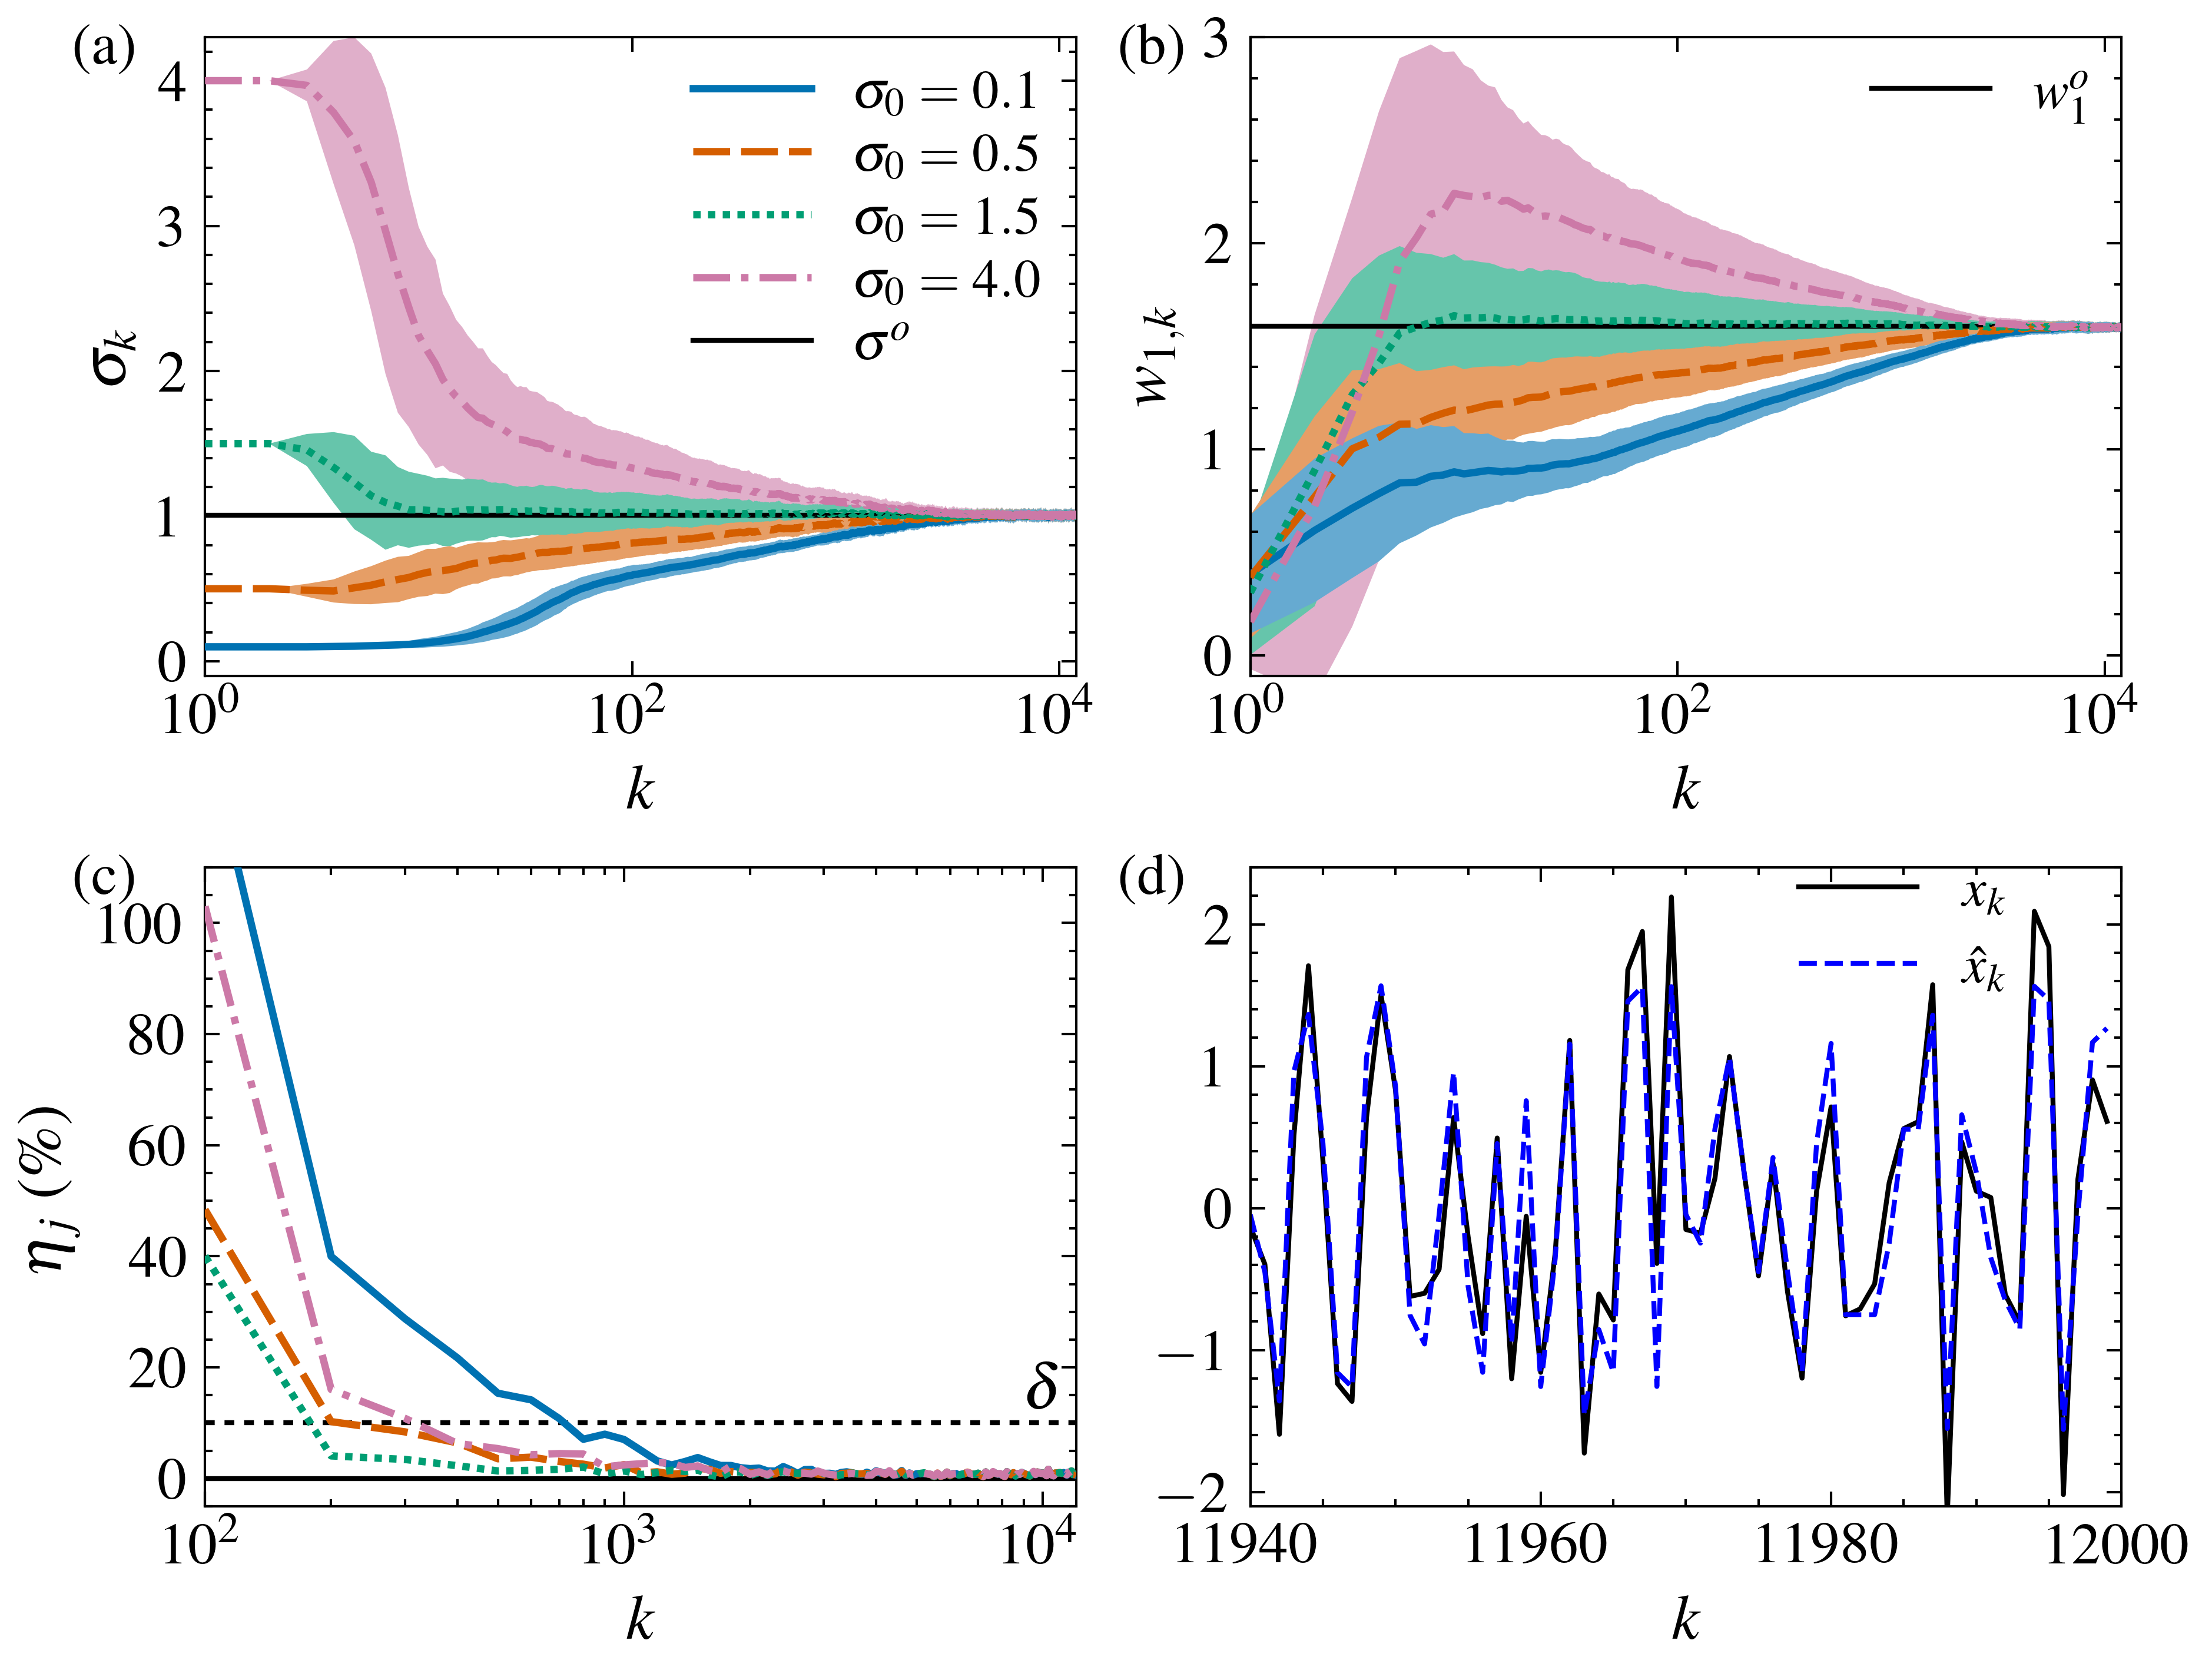

In [7]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

# -------------------- 双子图出版图 (Fig. 2) --------------------
try:
    import scienceplots  # noqa: F401
    # 1. 优先激活 IEEE 官方标准样式
    plt.style.use(["science", "ieee"])
    
    # 2. 核心修改：覆盖 scienceplots 默认的小字号，强制放大字号以应对 LaTeX 50% 缩放
    matplotlib.rcParams.update({
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 13,             # 全局基准字号
        "axes.titlesize": 13,        # 子图标题 (a,b,c,d) 的字号
        "axes.labelsize": 13,        # X/Y 轴标签 (labels) 的字号
        "xtick.labelsize": 12,       # X 轴刻度 (ticks) 的字号
        "ytick.labelsize": 12,       # Y 轴刻度 (ticks) 的字号
        "legend.fontsize": 11,       # 图例字号 (稍微小一点防止遮挡曲线)
        "axes.unicode_minus": False,
        "ps.fonttype": 42,           # 保证 EPS 字体正确嵌入
        "pdf.fonttype": 42           # 保证 PDF 字体正确嵌入
    })
except ImportError:
    # 未安装 scienceplots 时的备用样式
    matplotlib.rcParams.update({
        "font.family": "serif", 
        "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "DejaVu Serif"],
        "mathtext.fontset": "stix", 
        "font.size": 14, 
        "axes.titlesize": 16,
        "axes.labelsize": 16, 
        "legend.fontsize": 13,
        "xtick.labelsize": 14, 
        "ytick.labelsize": 14, 
        "axes.unicode_minus": False,
        "axes.linewidth": 0.6, 
        "ps.fonttype": 42, "pdf.fonttype": 42,
    })

# ============================================================
# Cell 7. Fig. 2
# ============================================================
def lighten(color, amount):
    """Mix a color with white (EPS-safe shading instead of transparency)."""
    import matplotlib.colors as mc
    c = np.array(mc.to_rgb(color))
    return tuple(1.0 - amount * (1.0 - c))

COLORS = {0.1: "#0072B2", 0.5: "#D55E00", 1.5: "#009E73", 4.0: "#CC79A7"}
DASHES = {0.1: "-", 0.5: (0, (5, 1.5)), 1.5: (0, (1, 1)), 4.0: (0, (5, 1.5, 1, 1.5))}
kk = np.arange(1, K_STAT + 1)
kb = (np.arange(K_STAT // BLOCK) + 1) * BLOCK

# 保持 7.0 英寸宽度，供 LaTeX 缩小使用
fig, axes = plt.subplots(2, 2, figsize=(7.0, 5.4))
plt.subplots_adjust(hspace=0.3, wspace=0.2)  # 稍微增加了 hspace 以容纳更大的字体
ax_a, ax_b, ax_c, ax_d = axes.flatten()

# 绘制阴影（逆序以防止遮挡）
for s0 in reversed(SIGMA0_LIST):
    m = MET_A[s0]
    for ax, tr in ((ax_a, m["sigma_traj"]), (ax_b, m["w_traj"])):
        mu_, sd_ = tr.mean(0), tr.std(0, ddof=1)
        ax.fill_between(kk, mu_ - sd_, mu_ + sd_, color=lighten(COLORS[s0], 0.6), edgecolor="none", zorder=1)

# 绘制实线
# 绘制实线 (去掉了冗余的 w_0=0，并且只在 ax_a 中加上 label)
for s0 in SIGMA0_LIST:
    m = MET_A[s0]
    ax_a.plot(kk, m["sigma_traj"].mean(0), color=COLORS[s0], ls=DASHES[s0], lw=1.5, zorder=3, label=rf"$\sigma_0={s0}$")
    ax_b.plot(kk, m["w_traj"].mean(0), color=COLORS[s0], ls=DASHES[s0], lw=1.5, zorder=3)
    ax_c.plot(kb, 100 * m["curve"], color=COLORS[s0], ls=DASHES[s0], lw=1.5, zorder=3)

# -------- 图 (a) --------
ax_a.axhline(REF1["sigma_o"], color="k", lw=1.0, zorder=2, label=r"$\sigma^o$")
ax_a.set(xscale="log", xlim=(1, K_STAT), ylim=(-0.1, 4.3), yticks=[0, 1, 2, 3, 4])
ax_a.set_ylabel(r"$\sigma_{k}$")

ax_a.legend(loc="upper right", ncol=1, frameon=False, handlelength=2.2, columnspacing=0.9, borderaxespad=0.2, labelspacing=0.25)

# -------- 图 (b) --------
ax_b.axhline(REF1["w_o"][1], color="k", lw=1.0, zorder=2, label=r"$w_1^o$")
ax_b.set(xscale="log", xlim=(1, K_STAT), ylim=(-0.1, 3.0))
ax_b.set_ylabel(r"$w_{1,k}$")
# 图(b)图例极其干净，只显示一条黑色参考线
ax_b.legend(loc="upper right", frameon=False, handlelength=2.2, borderaxespad=0.2)

# -------- 图 (c) --------
ax_c.axhline(100 * DELTA, color="k", lw=1.0, ls=(0, (2, 2)), zorder=2)
ax_c.axhline(0.0, color="k", lw=1.0, zorder=2)
ax_c.text(K_STAT * 0.9, 100 * DELTA + 2.5, r"$\delta$", color="k", ha="right", fontsize=13) 
ax_c.set(xscale="log", xlim=(BLOCK, K_STAT), ylim=(-5, 110), yticks=[0, 20, 40, 60, 80, 100]) 
ax_c.set_ylabel(r"$\eta_j$ (\%)")
# 彻底删除 ax_c.legend()，释放极其宝贵的留白空间！

# -------- 图 (d)：波形稳态追踪对比 --------
trial_idx = 0 
k_start = K_STAT - 60 
k_end = K_STAT
x_snip = xA[trial_idx, k_start:k_end]
err_snip = outA["err"][trial_idx, k_start:k_end]
xhat_snip = x_snip - err_snip 
time_snip = np.arange(k_start, k_end)

ax_d.plot(time_snip, x_snip, color="k", lw=1.0, label=r"$x_k$")
ax_d.plot(time_snip, xhat_snip, color="b", ls="--", lw=1.0, label=r"$\hat{x}_k$")
ax_d.set(xlim=(k_start, k_end), ylim=(-2.1, 2.4))
#ax_d.set_ylabel(r"$x_k$ and $\hat{x}_k$")
ax_d.legend(loc="upper right", bbox_to_anchor=(0.9, 1.05), frameon=False, handlelength=2.2, borderaxespad=0.2)

# -------- 统一设置 X 轴、刻度和内部子图序号 --------
for ax, lab in zip((ax_a, ax_b, ax_c, ax_d), "abcd"):
    # X轴标签
    ax.set_xlabel(r"$k$")
    ax.text(-0.15, 1.02, f"({lab})", transform=ax.transAxes, 
            fontsize=12, va="top", ha="left", 
            bbox=dict(facecolor="none", edgecolor="none", pad=1.5)) # 加个纯白底色防曲线穿模遮挡
    # 设置刻度朝内
    ax.tick_params(direction="in", which="both", top=True, right=True, width=0.5)

os.makedirs(OUT_DIR, exist_ok=True)  # 确保目录存在
for ext, kw in (("pdf", {}), ("eps", {}), ("png", {"dpi": 800})):
    fig.savefig(os.path.join(OUT_DIR, f"FigSPL2.{ext}"), bbox_inches="tight", **kw)
plt.show()

In [8]:
# ============================================================
# Cell 8. Experiment B (Table I): stationary inputs of unit power, N = 31
# ============================================================
t0 = time.time()
VOWEL = synth_vowel(K_STAT)
CONFIGS = (
    # key, label, stream kind, law, thresholds, group sizes
    ("G1", r"Gaussian, $M=1$", "gauss", LAW_G, (0.0,), (31,)),
    ("G2", r"Gaussian, $M=2$", "gauss", LAW_G, (-1.0, 1.0), (15, 16)),
    ("G3", r"Gaussian, $M=3$", "gauss", LAW_G, (-1.5, 0.0, 1.5), (10, 11, 10)),
    ("L1", r"Laplacian, $M=1$", "laplace", law_laplace(), (0.0,), (31,)),
    ("U1", r"Uniform, $M=1$", "uniform", law_uniform(), (0.0,), (31,)),
    ("S1", r"Sinusoid, $M=1$", "sine", law_sine(), (0.0,), (31,)),
    ("V1", r"Vowel, $M=1$", "vowel", law_empirical(VOWEL), (0.0,), (31,)),
)
S0_B = (0.1, 4.0)
TAB1 = {}
for ci, (key, label, kind, law, th, Ns) in enumerate(CONFIGS):
    ref = reference(law, th, Ns)
    x, xi = make_streams(kind, TRIALS, K_STAT, N_EL, tag=10 + ci)
    xi_t = dither_to_device(xi)
    rows = np.tile(np.arange(TRIALS), len(S0_B))
    o = simulate(x, xi_t, th, Ns, "ekf", sigma0=np.repeat(S0_B, TRIALS), x_idx=rows, lam_f=LAM_STAT,
                 rec_sigma=True)
    gen = simulate(x, xi_t, th, Ns, "genie", sigma0=ref["sigma_o"], w_init=ref["w_o"])
    del xi_t, xi
    track_sigma(o["sigma"], ref["sigma_o"])
    TAB1[key] = dict(label=label, ref=ref, genie_mse=float((gen["err"] ** 2).mean()), runs={})
    line = (f"{key}: sigma^o = {ref['sigma_o']:.3f}, zeta^o = {ref['zeta_o']:.4f} ({-10 * math.log10(ref['zeta_o']):.1f} dB), "
            f"local minima of zeta^min: {ref['n_local_min']}, genie MSE {TAB1[key]['genie_mse']:.4f}")
    for j, s0 in enumerate(S0_B):
        sl = slice(j * TRIALS, (j + 1) * TRIALS)
        m = convergence_metrics(o["err"][sl], gen["err"], o["sigma"][sl], tag=950 + 10 * ci + j)
        TAB1[key]["runs"][s0] = m
        line += (f"\n      sigma0 = {s0}: sigma = {m['sig_mean']:.3f} +- {m['sig_sd']:.3f}, misadj = {100 * m['misadj']:.1f}% "
                 f"(SE {100 * m['misadj_se']:.1f}), T = {m['T']:.0f} [{m['T_lo']:.0f}, {m['T_hi']:.0f}]")
        put(f"B.{key}.s{j}.sig", m["sig_mean"]); put(f"B.{key}.s{j}.mis", 100 * m["misadj"], "{:.1f}")
        put(f"B.{key}.s{j}.sd", m["sig_sd"]); put(f"B.{key}.s{j}.misse", 100 * m["misadj_se"], "{:.1f}")
        put(f"B.{key}.s{j}.T", fmt_T(m["T"]).strip("$"))
        put(f"B.{key}.s{j}.Tlo", fmt_T(m["T_lo"]).strip("$")); put(f"B.{key}.s{j}.Thi", fmt_T(m["T_hi"]).strip("$"))
    put(f"B.{key}.sigo", ref["sigma_o"]); put(f"B.{key}.zo", ref["zeta_o"])
    put(f"B.{key}.snr", -10 * math.log10(ref["zeta_o"]), "{:.1f}")
    print(line)

all_mis = [100 * TAB1[k]["runs"][s]["misadj"] for k in TAB1 for s in S0_B]
all_T = [TAB1[k]["runs"][s]["T"] for k in TAB1 for s in S0_B]
all_rel = [abs(TAB1[k]["runs"][s]["sig_mean"] / TAB1[k]["ref"]["sigma_o"] - 1) for k in TAB1 for s in S0_B]
put("B.mismax", max(all_mis), "{:.1f}"); put("B.mismin", min(all_mis), "{:.1f}")
put("B.Tmax", fmt_T(max(all_T)).strip("$")); put("B.Tmin", fmt_T(min(all_T)).strip("$"))
put("B.relmax", 100 * max(all_rel), "{:.1f}")
grp_rel = [abs(TAB1[k]["runs"][s]["sig_mean"] / TAB1[k]["ref"]["sigma_o"] - 1) for k in ("G2", "G3") for s in S0_B]
put("B.grp.relmax", 100 * max(grp_rel), "{:.1f}")
put("B.gain.G2", 100 * (1 - TAB1["G2"]["ref"]["zeta_o"] / TAB1["G1"]["ref"]["zeta_o"]), "{:.0f}")
put("B.gain.G3", 100 * (1 - TAB1["G3"]["ref"]["zeta_o"] / TAB1["G1"]["ref"]["zeta_o"]), "{:.0f}")

lines = []
for key in TAB1:
    r = TAB1[key]
    cells = [r["label"], f"${r['ref']['sigma_o']:.3f}$", f"${r['ref']['zeta_o']:.4f}$"]
    for s0 in S0_B:
        m = r["runs"][s0]
        cells += [f"${m['sig_mean']:.3f}\\pm{m['sig_sd']:.3f}$", f"${100 * m['misadj']:.1f}$", fmt_T(m["T"])]
    lines.append(" & ".join(cells) + r" \\")
with open(os.path.join(OUT_DIR, "table1.tex"), "w") as f:
    f.write("\n".join(lines) + "\n")
print(f"Experiment B: {time.time() - t0:.1f} s; wrote table1.tex")

G1: sigma^o = 1.007, zeta^o = 0.1029 (9.9 dB), local minima of zeta^min: 1, genie MSE 0.1031
      sigma0 = 0.1: sigma = 1.005 +- 0.012, misadj = 0.8% (SE 0.0), T = 700 [500, 700]
      sigma0 = 4.0: sigma = 1.005 +- 0.012, misadj = 0.8% (SE 0.0), T = 200 [200, 400]
G2: sigma^o = 0.589, zeta^o = 0.0590 (12.3 dB), local minima of zeta^min: 1, genie MSE 0.0589
      sigma0 = 0.1: sigma = 0.590 +- 0.004, misadj = 0.9% (SE 0.1), T = 100 [100, 100]
      sigma0 = 4.0: sigma = 0.590 +- 0.004, misadj = 0.9% (SE 0.1), T = 300 [300, 400]
G3: sigma^o = 0.413, zeta^o = 0.0426 (13.7 dB), local minima of zeta^min: 1, genie MSE 0.0427
      sigma0 = 0.1: sigma = 0.413 +- 0.003, misadj = 1.2% (SE 0.1), T = 100 [100, 100]
      sigma0 = 4.0: sigma = 0.413 +- 0.003, misadj = 1.2% (SE 0.1), T = 300 [300, 400]
L1: sigma^o = 1.170, zeta^o = 0.1699 (7.7 dB), local minima of zeta^min: 1, genie MSE 0.1707
      sigma0 = 0.1: sigma = 1.171 +- 0.027, misadj = 0.7% (SE 0.0), T = 600 [600, 1000]
      sigma0 = 4

In [9]:
# ============================================================
# Cell 9. Experiment C (Table II): amplitude steps, M = 1, theta_1 = 0, N = 31
#         Stream generators, tuning on development streams, Lloyd-Max reference
# ============================================================
N_WARM, N_ONLINE, CHANGE = 1000, 3000, 1500
K_TRK = N_WARM + N_ONLINE
SIGMA0_TRK = 0.5
CASES = (("Stationary", 1.0), ("$0.1$", 0.1), ("$0.5$", 0.5), ("$2$", 2.0), ("$10$", 10.0))
DEV_STEPS = (0.1, 0.2, 1.0 / 3.0, 3.0, 5.0, 10.0)
LAM_GRID = (0.8, 0.85, 0.9, 0.93, 0.95, 0.97, 0.98, 0.99, 0.995, 1.0)
METHODS = {
    "RLS--EKF": ("ekf", "q", np.logspace(-5, 0, 11)),
    "Normalized gradient": ("ngrad", "mu", np.logspace(-4, 0, 13)),
    "Gradient": ("grad", "mu", np.logspace(-4, 1, 21)),
    "Fixed $\\sigma$": ("fixed", "sigma0", np.logspace(-1, 1.3, 47)),
}
SEG = [(N_WARM, N_WARM + CHANGE), (N_WARM + CHANGE, K_TRK)]     # pre-change and post-change windows


def step_streams(steps, L, tag):
    """For each amplitude step A: L streams x_k = A_k u_k, u_k ~ N(0,1), A_k = 1 before the change and A after.
    The same u_k and quantizer noise are reused for every A (paired design)."""
    rngs = child_rngs(tag, L)
    u = np.stack([r.standard_normal(K_TRK) for r in rngs])
    xi = np.stack([r.standard_normal((K_TRK, N_EL), dtype=np.float32) for r in rngs])
    gain = lambda A: np.where(np.arange(K_TRK) < N_WARM + CHANGE, 1.0, A)
    x = np.concatenate([u * gain(A) for A in steps])
    return x, xi, np.tile(np.arange(L), len(steps))


def tune(name, dev_x, dev_xi_t, dev_idx):
    """Grid search over (method parameter, lambda_f): minimize the NMSE averaged over the two windows
    and over the development streams."""
    rule, pname, grid = METHODS[name]
    mesh_p, mesh_l = np.meshgrid(np.asarray(grid, float), np.asarray(LAM_GRID, float), indexing="ij")
    pv, lv = mesh_p.ravel(), mesh_l.ravel()
    n, C = dev_x.shape[0], pv.size
    kw = {pname: np.repeat(pv, n)}
    if pname != "sigma0":
        kw["sigma0"] = SIGMA0_TRK
    out = simulate(dev_x, dev_xi_t, TH1, NS1, rule, lam_f=np.repeat(lv, n), x_idx=np.tile(np.arange(n), C),
                   xi_idx=np.tile(dev_idx, C), rec_err=False, seg_bounds=SEG, **kw)
    crit = (out["seg_err"] / out["seg_pow"]).mean(1)
    crit = np.where(np.isfinite(crit), crit, np.inf).reshape(C, n).mean(1)
    j = int(np.argmin(crit))
    return dict(rule=rule, pname=pname, p=float(pv[j]), lam=float(lv[j]), crit=float(crit[j]))


# ---- empirical Lloyd-Max quantizer with 31 thresholds, refitted every 128 samples on the last 256
REFIT_EVERY, REFIT_WIN = 128, 256


def _uniform_init(data, n_thr=N_EL):
    c0 = float(np.mean(data))

    def build(delta):
        thr = c0 + (np.arange(n_thr) - (n_thr - 1) / 2.0) * delta
        lev = np.concatenate([[thr[0] - delta / 2], 0.5 * (thr[:-1] + thr[1:]), [thr[-1] + delta / 2]])
        return thr, lev

    def mse(delta):
        thr, lev = build(delta)
        return np.mean((data - lev[np.searchsorted(thr, data)]) ** 2)

    span = float(np.max(np.abs(data - c0)))
    grid = np.linspace(span / (4 * n_thr), 4 * span / n_thr, 400)
    i = int(np.argmin([mse(dl) for dl in grid]))
    res = optimize.minimize_scalar(mse, bounds=(grid[max(i - 1, 0)], grid[min(i + 1, grid.size - 1)]),
                                   method="bounded", options={"xatol": 1e-9})
    return build(res.x)


def lloyd_max_fit(data, n_thr=N_EL, iters=10000, tol=1e-12):
    data = np.asarray(data, float)
    lev = _uniform_init(data, n_thr)[1]
    for _ in range(iters):
        thr = 0.5 * (lev[:-1] + lev[1:])
        ix = np.searchsorted(thr, data)
        cnt = np.bincount(ix, minlength=n_thr + 1)
        sums = np.bincount(ix, weights=data, minlength=n_thr + 1)
        new = np.sort(np.where(cnt > 0, sums / np.maximum(cnt, 1), lev))
        done = np.max(np.abs(new - lev)) < tol
        lev = new
        if done:
            break
    return 0.5 * (lev[:-1] + lev[1:]), lev


def online_lm(x_warm, x_on):
    thr, lev = lloyd_max_fit(x_warm)
    hist = np.concatenate([x_warm, x_on])
    xhat = np.empty_like(x_on)
    n_seen, i = x_warm.size, 0
    while i < x_on.size:
        nxt = (n_seen // REFIT_EVERY + 1) * REFIT_EVERY
        j = min(i + (nxt - n_seen), x_on.size)
        xhat[i:j] = lev[np.searchsorted(thr, x_on[i:j])]
        n_seen += j - i
        i = j
        if n_seen % REFIT_EVERY == 0 and i < x_on.size:
            thr, lev = lloyd_max_fit(hist[max(0, n_seen - REFIT_WIN):n_seen])
    return xhat

In [10]:
# ============================================================
# Cell 10. Experiment C: tune, test, paired comparison, Table II
# ============================================================
t0 = time.time()
DEV_L = 4
dev_x, dev_xi, dev_idx = step_streams(DEV_STEPS, DEV_L, tag=40)
dev_xi_t = dither_to_device(dev_xi)
TUNED = {}
print("Parameters selected on the development streams (steps A = 0.1, 0.2, 1/3, 3, 5, 10):")
for name in METHODS:
    TUNED[name] = tune(name, dev_x, dev_xi_t, dev_idx)
    t = TUNED[name]
    print(f"  {name:20s}: {t['pname']} = {t['p']:.4g}, lambda_f = {t['lam']:g}  (criterion {t['crit']:.4f})")
del dev_xi_t, dev_xi
put("C.ekf.q", f"{TUNED['RLS--EKF']['p']:.2g}"); put("C.ekf.lam", f"{TUNED['RLS--EKF']['lam']:g}")
put("C.ng.mu", f"{TUNED['Normalized gradient']['p']:.2g}"); put("C.ng.lam", f"{TUNED['Normalized gradient']['lam']:g}")
put("C.gr.mu", f"{TUNED['Gradient']['p']:.2g}"); put("C.gr.lam", f"{TUNED['Gradient']['lam']:g}")
put("C.fx.sig", f"{TUNED['Fixed $' + chr(92) + 'sigma$']['p']:.2f}"); put("C.fx.lam", f"{TUNED['Fixed $' + chr(92) + 'sigma$']['lam']:g}")

test_x, test_xi, test_idx = step_streams([A for _, A in CASES], TRIALS, tag=41)
test_xi_t = dither_to_device(test_xi)
nC = len(CASES)
NM = {}
for name, t in TUNED.items():
    kw = {t["pname"]: t["p"]}
    if t["pname"] != "sigma0":
        kw["sigma0"] = SIGMA0_TRK
    o = simulate(test_x, test_xi_t, TH1, NS1, t["rule"], lam_f=t["lam"], xi_idx=test_idx,
                 rec_err=False, seg_bounds=SEG, **kw)
    NM[name] = (o["seg_err"][:, 1] / o["seg_pow"][:, 1]).reshape(nC, TRIALS)     # post-change window
del test_xi_t, test_xi

lm = np.empty((nC, TRIALS))
sl_post = slice(CHANGE, N_ONLINE)
for c in range(nC):
    for i in range(TRIALS):
        row = test_x[c * TRIALS + i]
        xh = online_lm(row[:N_WARM], row[N_WARM:])
        xo = row[N_WARM:]
        lm[c, i] = np.sum((xo[sl_post] - xh[sl_post]) ** 2) / np.sum(xo[sl_post] ** 2)
NM["LM ($31$ thresholds)"] = lm

ssr = list(METHODS)
means = np.array([[NM[n][c].mean() for c in range(nC)] for n in ssr])
best = means.argmin(0)
# paired t-test (same inputs and noise) of every SSR method against the best one in each column
PVAL = np.ones((len(ssr), nC))
for c in range(nC):
    for j, n in enumerate(ssr):
        if j != best[c]:
            PVAL[j, c] = stats.ttest_rel(NM[n][c], NM[ssr[best[c]]][c]).pvalue

print(f"\nTable II: NMSE x 1e-3 over the {N_ONLINE - CHANGE} post-change samples, mean +- SD over {TRIALS} trials")
print(f"{'Method':22s}" + "".join(f"{lab:>18s}" for lab, _ in CASES))
for n in NM:
    prec = 2 if n.startswith("LM") else 1
    print(f"{n:22s}" + "".join(f"{1e3 * NM[n][c].mean():11.{prec}f}+-{1e3 * NM[n][c].std(ddof=1):5.{prec}f}" for c in range(nC)))
print("paired p-values against the best SSR method of each column:")
for j, n in enumerate(ssr):
    print(f"{n:22s}" + "".join(f"{PVAL[j, c]:18.2g}" for c in range(nC)))

lines = []
for j, n in enumerate(ssr):
    cells = []
    for c in range(nC):
        mu_, sd_ = 1e3 * NM[n][c].mean(), 1e3 * NM[n][c].std(ddof=1)
        txt = f"{mu_:.1f}\\pm{sd_:.1f}"
        cells.append(f"$\\bm{{{txt}}}$" if (j == best[c] or PVAL[j, c] >= 0.05) else f"${txt}$")
    lines.append(f"{n} & " + " & ".join(cells) + r" \\")
lines.append(r"\midrule")
lines.append("LM ($31$ thresholds) & " + " & ".join(
    f"${1e3 * lm[c].mean():.1f}\\pm{1e3 * lm[c].std(ddof=1):.1f}$" for c in range(nC)) + r" \\")
with open(os.path.join(OUT_DIR, "table2.tex"), "w") as f:
    f.write("\n".join(lines) + "\n")

for j, n in enumerate(ssr):
    for c in range(nC):
        txt = f"{1e3 * NM[n][c].mean():.1f}\\pm{1e3 * NM[n][c].std(ddof=1):.1f}"
        put(f"T2.{('ekf', 'ng', 'gr', 'fx')[j]}.c{c}",
            f"$\\bm{{{txt}}}$" if (j == best[c] or PVAL[j, c] >= 0.05) else f"${txt}$")
for c in range(nC):
    put(f"T2.lm.c{c}", f"${1e3 * lm[c].mean():.1f}\\pm{1e3 * lm[c].std(ddof=1):.1f}$")
    put(f"C.best.c{c}", ("ekf", "ng", "gr", "fx")[best[c]])
P_MAX = float(PVAL[PVAL < 1].max())
_e = int(math.floor(math.log10(P_MAX)))
put("C.pmax", f"{P_MAX / 10 ** _e:.0f}\\times10^{{{_e}}}")
put("C.A01.ratio", NM["RLS--EKF"][1].mean() / REF1["zeta_o"], "{:.1f}")
short = {"RLS--EKF": "ekf", "Normalized gradient": "ng", "Gradient": "gr", "Fixed $\\sigma$": "fx", "LM ($31$ thresholds)": "lm"}
for n in NM:
    for c in range(nC):
        put(f"C.{short[n]}.c{c}", 1e3 * NM[n][c].mean(), "{:.1f}")
ekf = NM["RLS--EKF"]
put("C.stat.cost", 100 * (ekf[0].mean() / REF1["zeta_o"] - 1), "{:.0f}")
for b in ("ng", "gr", "fx"):
    full = [k for k, v in short.items() if v == b][0]
    red = [100 * (1 - ekf[c].mean() / NM[full][c].mean()) for c in range(nC)]
    for c in range(nC):
        put(f"C.red.{b}.c{c}", red[c], "{:.0f}")
print(f"Experiment C: {time.time() - t0:.1f} s; wrote table2.tex")

Parameters selected on the development streams (steps A = 0.1, 0.2, 1/3, 3, 5, 10):
  RLS--EKF            : q = 0.003162, lambda_f = 0.93  (criterion 0.1390)
  Normalized gradient : mu = 0.04642, lambda_f = 0.93  (criterion 0.1439)
  Gradient            : mu = 0.5623, lambda_f = 0.95  (criterion 0.1671)
  Fixed $\sigma$      : sigma0 = 0.4467, lambda_f = 0.95  (criterion 0.2618)

Table II: NMSE x 1e-3 over the 1500 post-change samples, mean +- SD over 100 trials
Method                        Stationary             $0.1$             $0.5$               $2$              $10$
RLS--EKF                    116.0+-  5.4      284.0+- 39.1      120.6+-  5.7      118.0+-  5.5      130.5+-  6.4
Normalized gradient         117.3+-  5.4      310.8+- 40.6      121.8+-  5.7      119.3+-  5.5      148.3+-  9.1
Gradient                    118.8+-  5.4      591.1+-157.1      126.3+-  5.6      120.0+-  5.5      124.3+-  5.6
Fixed $\sigma$              180.1+-  7.7      647.2+- 37.6      114.2+-  5.9     

In [11]:
# ============================================================
# Cell 11. Numerical check of scale equivariance (letter, Sec. III):
#          scaling x_k, theta_m and sigma_0 by A scales sigma_k and eps_k by A exactly
# ============================================================
xE, xiE = make_streams("gauss", 4, 2000, N_EL, tag=60)
xiE_t = dither_to_device(xiE)
base = simulate(xE, xiE_t, (-1.0, 1.0), (15, 16), "ekf", sigma0=0.5, rec_sigma=True)
dev_max = 0.0
for A in (1e-3, 0.1, 10.0, 1e3):
    sc = simulate(A * xE, xiE_t, (-A, A), (15, 16), "ekf", sigma0=0.5 * A, rec_sigma=True)
    dev_sig = np.max(np.abs(sc["sigma"] / (A * base["sigma"]) - 1.0))
    dev_err = np.max(np.abs(sc["err"] - A * base["err"]) / A)
    dev_max = max(dev_max, dev_sig, dev_err)
    print(f"A = {A:7g}: max |sigma_k/(A sigma_k^(1)) - 1| = {dev_sig:.1e}, max |eps_k - A eps_k^(1)|/A = {dev_err:.1e}")
put("E.dev", f"10^{{{int(math.ceil(math.log10(dev_max)))}}}")
del xiE_t, xiE

A =   0.001: max |sigma_k/(A sigma_k^(1)) - 1| = 9.1e-15, max |eps_k - A eps_k^(1)|/A = 6.1e-15
A =     0.1: max |sigma_k/(A sigma_k^(1)) - 1| = 3.7e-15, max |eps_k - A eps_k^(1)|/A = 5.1e-15
A =      10: max |sigma_k/(A sigma_k^(1)) - 1| = 3.3e-15, max |eps_k - A eps_k^(1)|/A = 5.2e-15
A =    1000: max |sigma_k/(A sigma_k^(1)) - 1| = 8.4e-15, max |eps_k - A eps_k^(1)|/A = 5.5e-15


In [12]:
# ============================================================
# Cell 12. Write every number quoted in the letter
# ============================================================
put("A.sigo", REF1["sigma_o"]); put("A.zo", REF1["zeta_o"]); put("A.wo", REF1["w_o"][1])
put("trials", str(TRIALS)); put("K", str(K_STAT)); put("W", str(BLOCK)); put("late", str(LATE))
put("delta", f"{100 * DELTA:.0f}"); put("q", "10^{-4}" if Q_SCALE == 1e-4 else f"{Q_SCALE:g}")
put("lamstat", f"{LAM_STAT:g}")
put("all.runs", str(SIG_RANGE["runs"])); put("all.bad", str(SIG_RANGE["bad"]))
put("all.lo", SIG_RANGE["lo"], "{:.2f}"); put("all.hi", SIG_RANGE["hi"], "{:.1f}")
print(f"RLS-EKF runs: {SIG_RANGE['runs']}, non-finite: {SIG_RANGE['bad']}, "
      f"sigma_k/sigma^o within [{SIG_RANGE['lo']:.3g}, {SIG_RANGE['hi']:.3g}]")
with open(os.path.join(OUT_DIR, "ssr_results.tex"), "w") as f:
    f.write("% Generated by SSR_RLS_EKF.ipynb -- do not edit by hand.\n")
    for k_, v_ in sorted(RES.items()):
        f.write(f"\\resdef{{{k_}}}{{{v_}}}\n")
with open(os.path.join(OUT_DIR, "ssr_results.json"), "w") as f:
    json.dump(RES, f, indent=1, sort_keys=True)
print(f"wrote {len(RES)} values to {OUT_DIR}/ssr_results.tex and ssr_results.json")

RLS-EKF runs: 1800, non-finite: 0, sigma_k/sigma^o within [0.0513, 24]
wrote 272 values to D:\IEEE 2025 Adaptive weighted SSR/ssr_results.tex and ssr_results.json


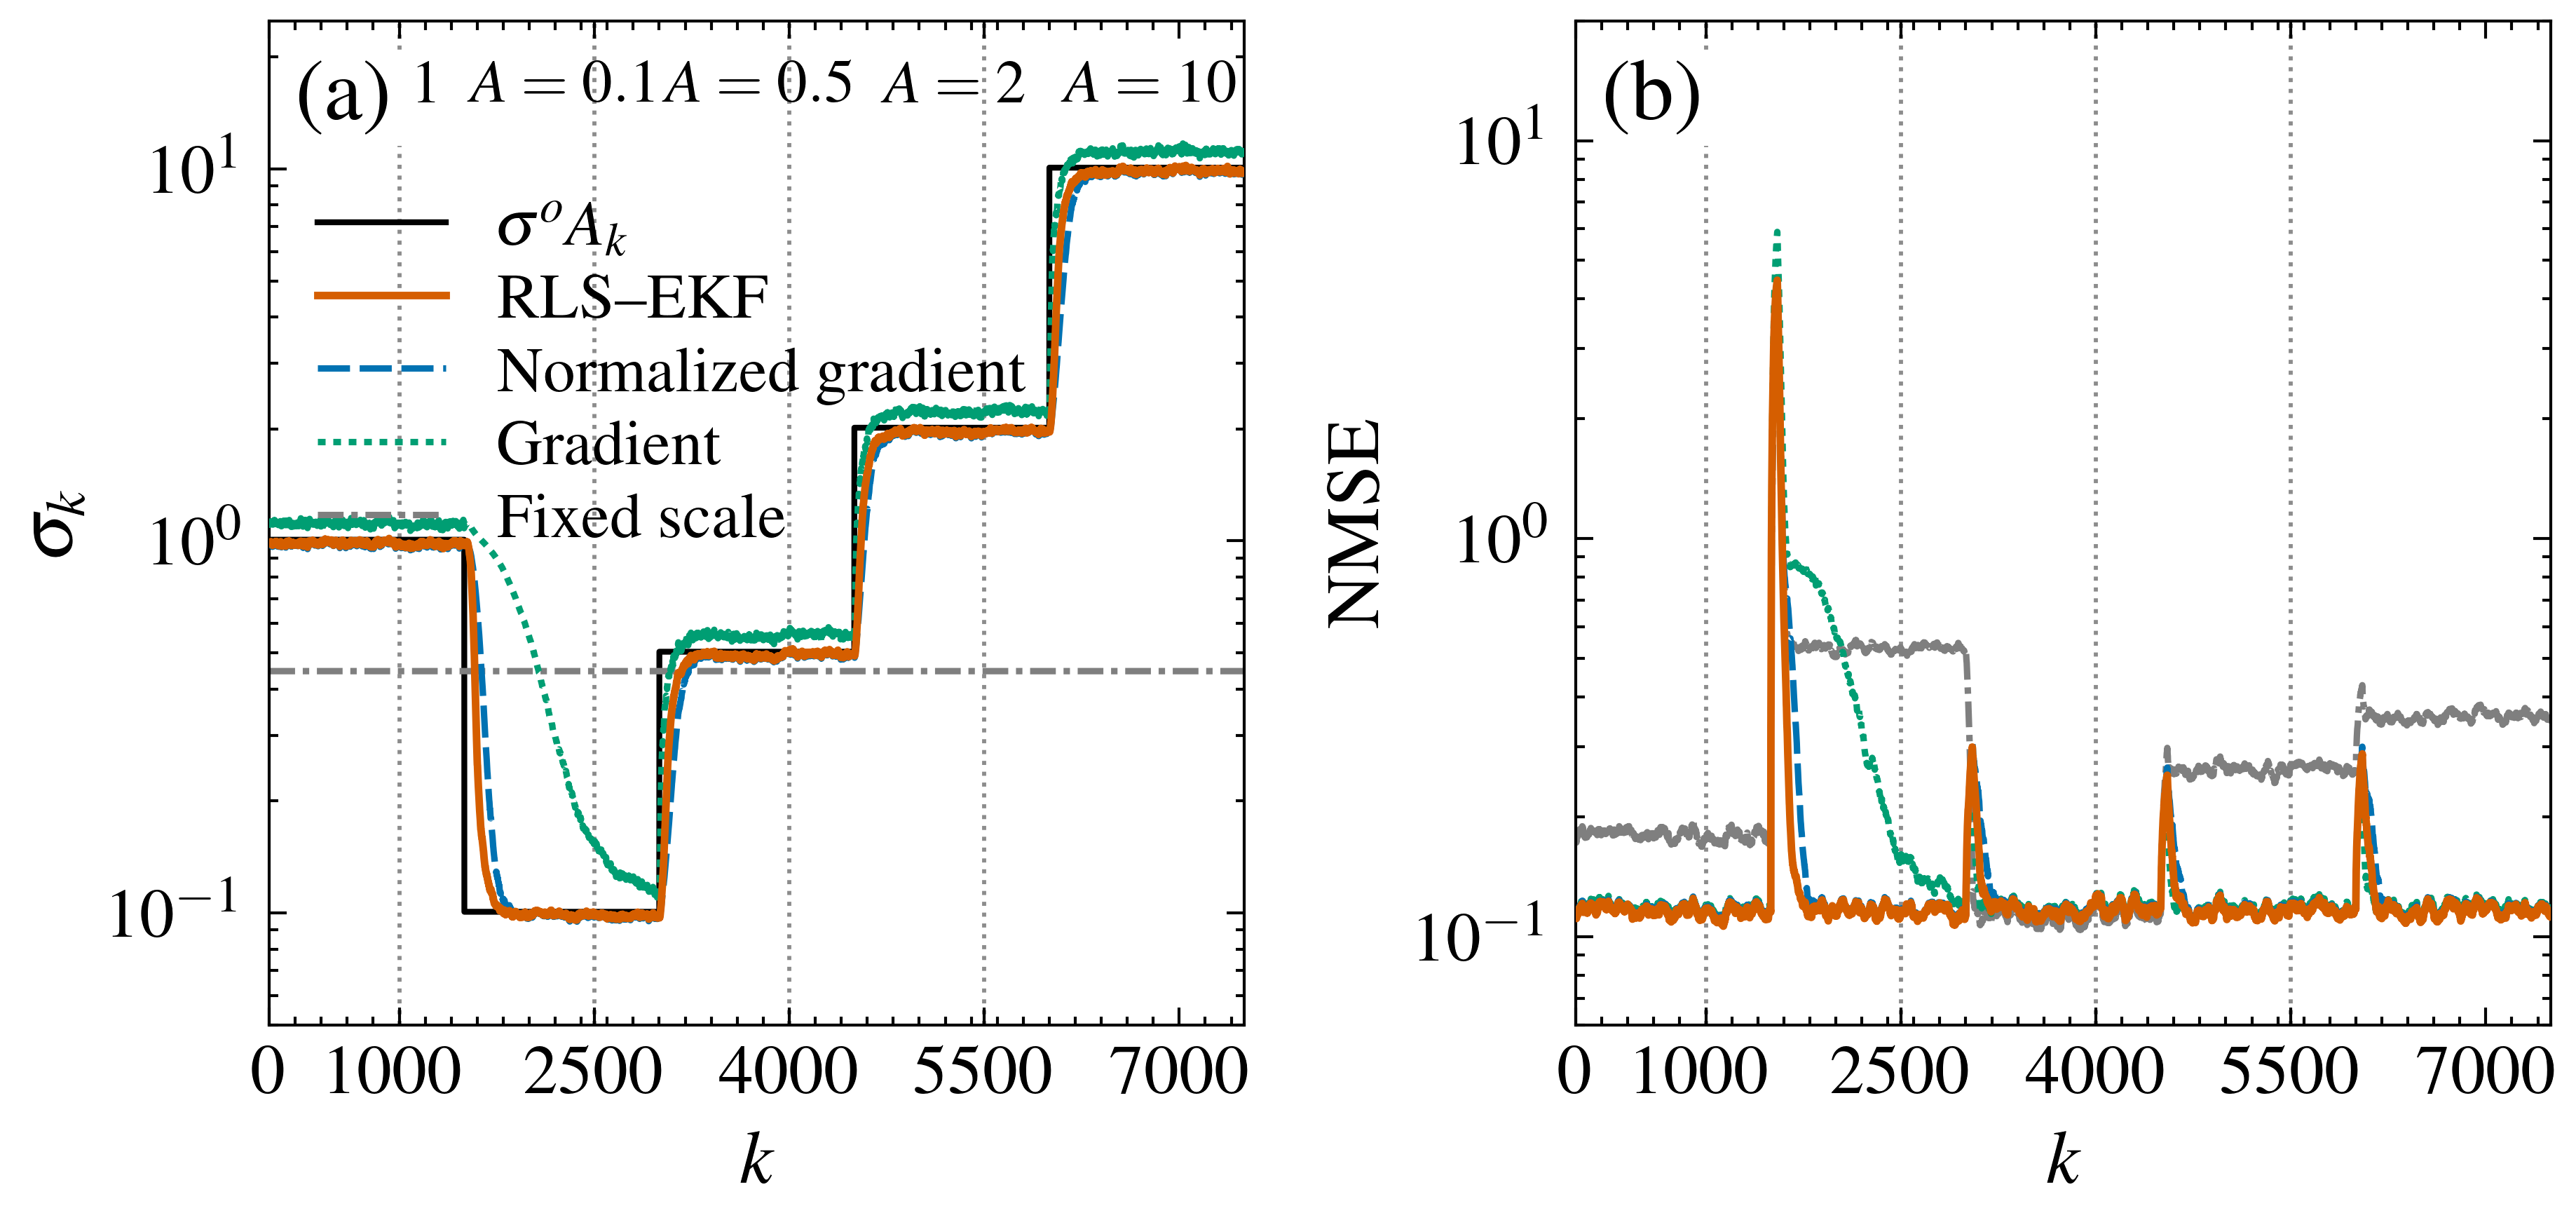

In [13]:
# ============================================================
# Cell 11. Fig. 3: Multi-step amplitude tracking (sigma_k & NMSE)
# ============================================================
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.signal import lfilter

try:
    import scienceplots  # noqa: F401
    # 1. 优先激活 IEEE 官方标准样式
    plt.style.use(["science", "ieee"])
    
    # 2. 核心修改：覆盖 scienceplots 默认的小字号，强制放大字号以应对 LaTeX 50% 缩放
    matplotlib.rcParams.update({
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 13,             # 全局基准字号
        "axes.titlesize": 13,        # 子图标题 (a,b,c,d) 的字号
        "axes.labelsize": 13,        # X/Y 轴标签 (labels) 的字号
        "xtick.labelsize": 12,       # X 轴刻度 (ticks) 的字号
        "ytick.labelsize": 12,       # Y 轴刻度 (ticks) 的字号
        "legend.fontsize": 11,       # 图例字号 (稍微小一点防止遮挡曲线)
        "axes.unicode_minus": False,
        "ps.fonttype": 42,           # 保证 EPS 字体正确嵌入
        "pdf.fonttype": 42           # 保证 PDF 字体正确嵌入
    })
except ImportError:
    # 未安装 scienceplots 时的备用样式
    matplotlib.rcParams.update({
        "font.family": "serif", 
        "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "DejaVu Serif"],
        "mathtext.fontset": "stix", 
        "font.size": 14, 
        "axes.titlesize": 16,
        "axes.labelsize": 16, 
        "legend.fontsize": 13,
        "xtick.labelsize": 14, 
        "ytick.labelsize": 14, 
        "axes.unicode_minus": False,
        "axes.linewidth": 0.6, 
        "ps.fonttype": 42, "pdf.fonttype": 42,
    })

# ---- 1. 构造与 Experiment C 完全一致的阶梯跳变信号 ----
WARMUP_C = 1000
SEG_LEN = 1500
AMP_SEQ = (1.0, 0.1, 0.5, 2.0, 10.0)   # 预热后在线阶段每隔 1500 点依次变化
K_ONLINE = SEG_LEN * len(AMP_SEQ)      # 7500 个在线采样点
K_TOTAL = WARMUP_C + K_ONLINE          # 8500 个总采样点

# 构造逐点幅度包络 A_k
A_full = np.ones(K_TOTAL, dtype=np.float64)
for idx, amp in enumerate(AMP_SEQ):
    s = WARMUP_C + idx * SEG_LEN
    e = WARMUP_C + (idx + 1) * SEG_LEN
    A_full[s:e] = amp

# 生成独立的高斯输入流与抖动噪声（与前文互不干涉）
z_trk, xi_trk = make_streams("gauss", TRIALS, K_TOTAL, N_EL, tag=310)
x_trk = z_trk * A_full[None, :]
xi_trk_t = dither_to_device(xi_trk)

# ---- 2. 使用 Cell 10 调优后的最优参数运行 4 种方法 ----
# 若内存中保留了 Cell 10 的调参变量则优先复用，否则使用精确网格搜索值
TUNED_CFG = {
    "RLS--EKF":            dict(rule="ekf",   sigma0=REF1["sigma_o"], lam_f=0.93, q=0.003162, mu=0.0),
    "Normalized gradient": dict(rule="ngrad", sigma0=REF1["sigma_o"], lam_f=0.93, q=0.0,      mu=0.04642),
    "Gradient":            dict(rule="grad",  sigma0=REF1["sigma_o"], lam_f=0.95, q=0.0,      mu=0.5623),
    "Fixed scale":         dict(rule="fixed", sigma0=0.4467,          lam_f=0.95, q=0.0,      mu=0.0),
}

# 若 Cell 10 中存在 BEST / TUNED 等字典，自动同步参数
for _cand_name in ("BEST", "TUNED", "best_params"):
    if _cand_name in globals() and isinstance(globals()[_cand_name], dict):
        _src = globals()[_cand_name]
        for _k_lbl, _k_key in [("RLS--EKF", "ekf"), ("Normalized gradient", "ngrad"),
                                ("Gradient", "grad"), ("Fixed scale", "fixed")]:
            if _k_key in _src:
                for _p in ("lam_f", "q", "mu", "sigma0"):
                    if _p in _src[_k_key]:
                        TUNED_CFG[_k_lbl][_p] = float(_src[_k_key][_p])

SMOOTH_WIN = 50  # 因果滑动窗口长度（50 样本）
b_causal = np.ones(SMOOTH_WIN, dtype=np.float64) / SMOOTH_WIN

sigma_mean_on = {}
nmse_smooth_on = {}
A_on = A_full[WARMUP_C:]

for label, cfg in TUNED_CFG.items():
    out = simulate(
        x_trk, xi_trk_t, TH1, NS1,
        rule=cfg["rule"],
        sigma0=cfg["sigma0"],
        lam_f=cfg["lam_f"],
        q=cfg["q"],
        mu=cfg["mu"],
        rec_err=True,
        rec_sigma=True,
    )
    # 1) sigma_k 系综平均（截取预热后的在线阶段）
    sigma_mean_on[label] = out["sigma"][:, WARMUP_C:].mean(axis=0)

    # 2) 瞬时系综 NMSE = E[eps_k^2] / A_k^2，先在全序列做因果平滑再截取在线阶段，消除边界效应
    inst_nmse = (out["err"] ** 2).mean(axis=0) / (A_full ** 2)
    smooth_nmse = lfilter(b_causal, [1.0], inst_nmse)
    nmse_smooth_on[label] = smooth_nmse[WARMUP_C:]

del xi_trk_t, xi_trk

# ---- 3. 绘制 1x2 左右双子图 (Fig. 3) ----
STYLES_C = {
    "RLS--EKF":            dict(color="#D55E00", ls="-",                  lw=1.3, zorder=5),
    "Normalized gradient": dict(color="#0072B2", ls=(0, (5, 1.5)),        lw=1.1, zorder=4),
    "Gradient":            dict(color="#009E73", ls=(0, (1.2, 1.2)),      lw=1.1, zorder=3),
    "Fixed scale":         dict(color="#7F7F7F", ls=(0, (4, 1.2, 1, 1.2)),lw=1.1, zorder=2),
}

k_on = np.arange(1, K_ONLINE + 1)
step_ticks = [0, 1000, 2500, 4000, 5500, 7000]

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(7.0, 3.1))
plt.subplots_adjust(wspace=0.34)

# 左图 (a): 噪声尺度 sigma_k 追踪轨迹
ax_a.plot(k_on, REF1["sigma_o"] * A_on, color="k", lw=1.0, zorder=1, label=r"$\sigma^o A_k$")
for label in TUNED_CFG:
    st = STYLES_C[label]
    ax_a.plot(k_on, sigma_mean_on[label], color=st["color"], ls=st["ls"], lw=st["lw"], zorder=st["zorder"], label=label)

ax_a.set_yscale("log")
ax_a.set_xlim(0, K_ONLINE)
ax_a.set_ylim(0.05, 25.0)
ax_a.set_xticks(step_ticks)
ax_a.set_ylabel(r"$\sigma_k$")
ax_a.legend(loc="upper left", bbox_to_anchor=(0.01, 0.86), frameon=False,
            handlelength=2.0, labelspacing=0.22, borderaxespad=0.2)

# 顶部标注每段对应的 A_k 幅度值
for idx, amp in enumerate(AMP_SEQ):
    mid_k = (idx + 0.5) * SEG_LEN
    ax_a.text(mid_k, 16.5, rf"$A={amp:g}$", ha="center", va="center", fontsize=10.5, color="k")

# 右图 (b): 因果平滑后的瞬时 NMSE 学习曲线
for label in TUNED_CFG:
    st = STYLES_C[label]
    ax_b.plot(k_on, nmse_smooth_on[label], color=st["color"], ls=st["ls"], lw=st["lw"], zorder=st["zorder"])

ax_b.set_yscale("log")
ax_b.set_xlim(0, K_ONLINE)
ax_b.set_ylim(0.06, 20.0)
ax_b.set_xticks(step_ticks)
ax_b.set_ylabel(r"$\mathrm{NMSE}$")

# 统一设置跳变虚线、内嵌子图编号 (a)/(b)、刻度
for ax, lab in zip((ax_a, ax_b), "ab"):
    for jump_k in step_ticks[1:-1]:
        ax.axvline(jump_k, color="0.55", ls=":", lw=0.7, zorder=0)
    ax.set_xlabel(r"$k$")
    ax.text(0.03, 0.96, f"({lab})", transform=ax.transAxes,
            fontsize=15, va="top", ha="left",
            bbox=dict(facecolor="white", edgecolor="none", pad=1.2))
    ax.tick_params(direction="in", which="both", top=True, right=True, width=0.5)

for ext, kw in (("pdf", {}), ("eps", {}), ("png", {"dpi": 1000})):
    fig.savefig(os.path.join(OUT_DIR, f"FigSPL3.{ext}"), bbox_inches="tight", **kw)
plt.show()

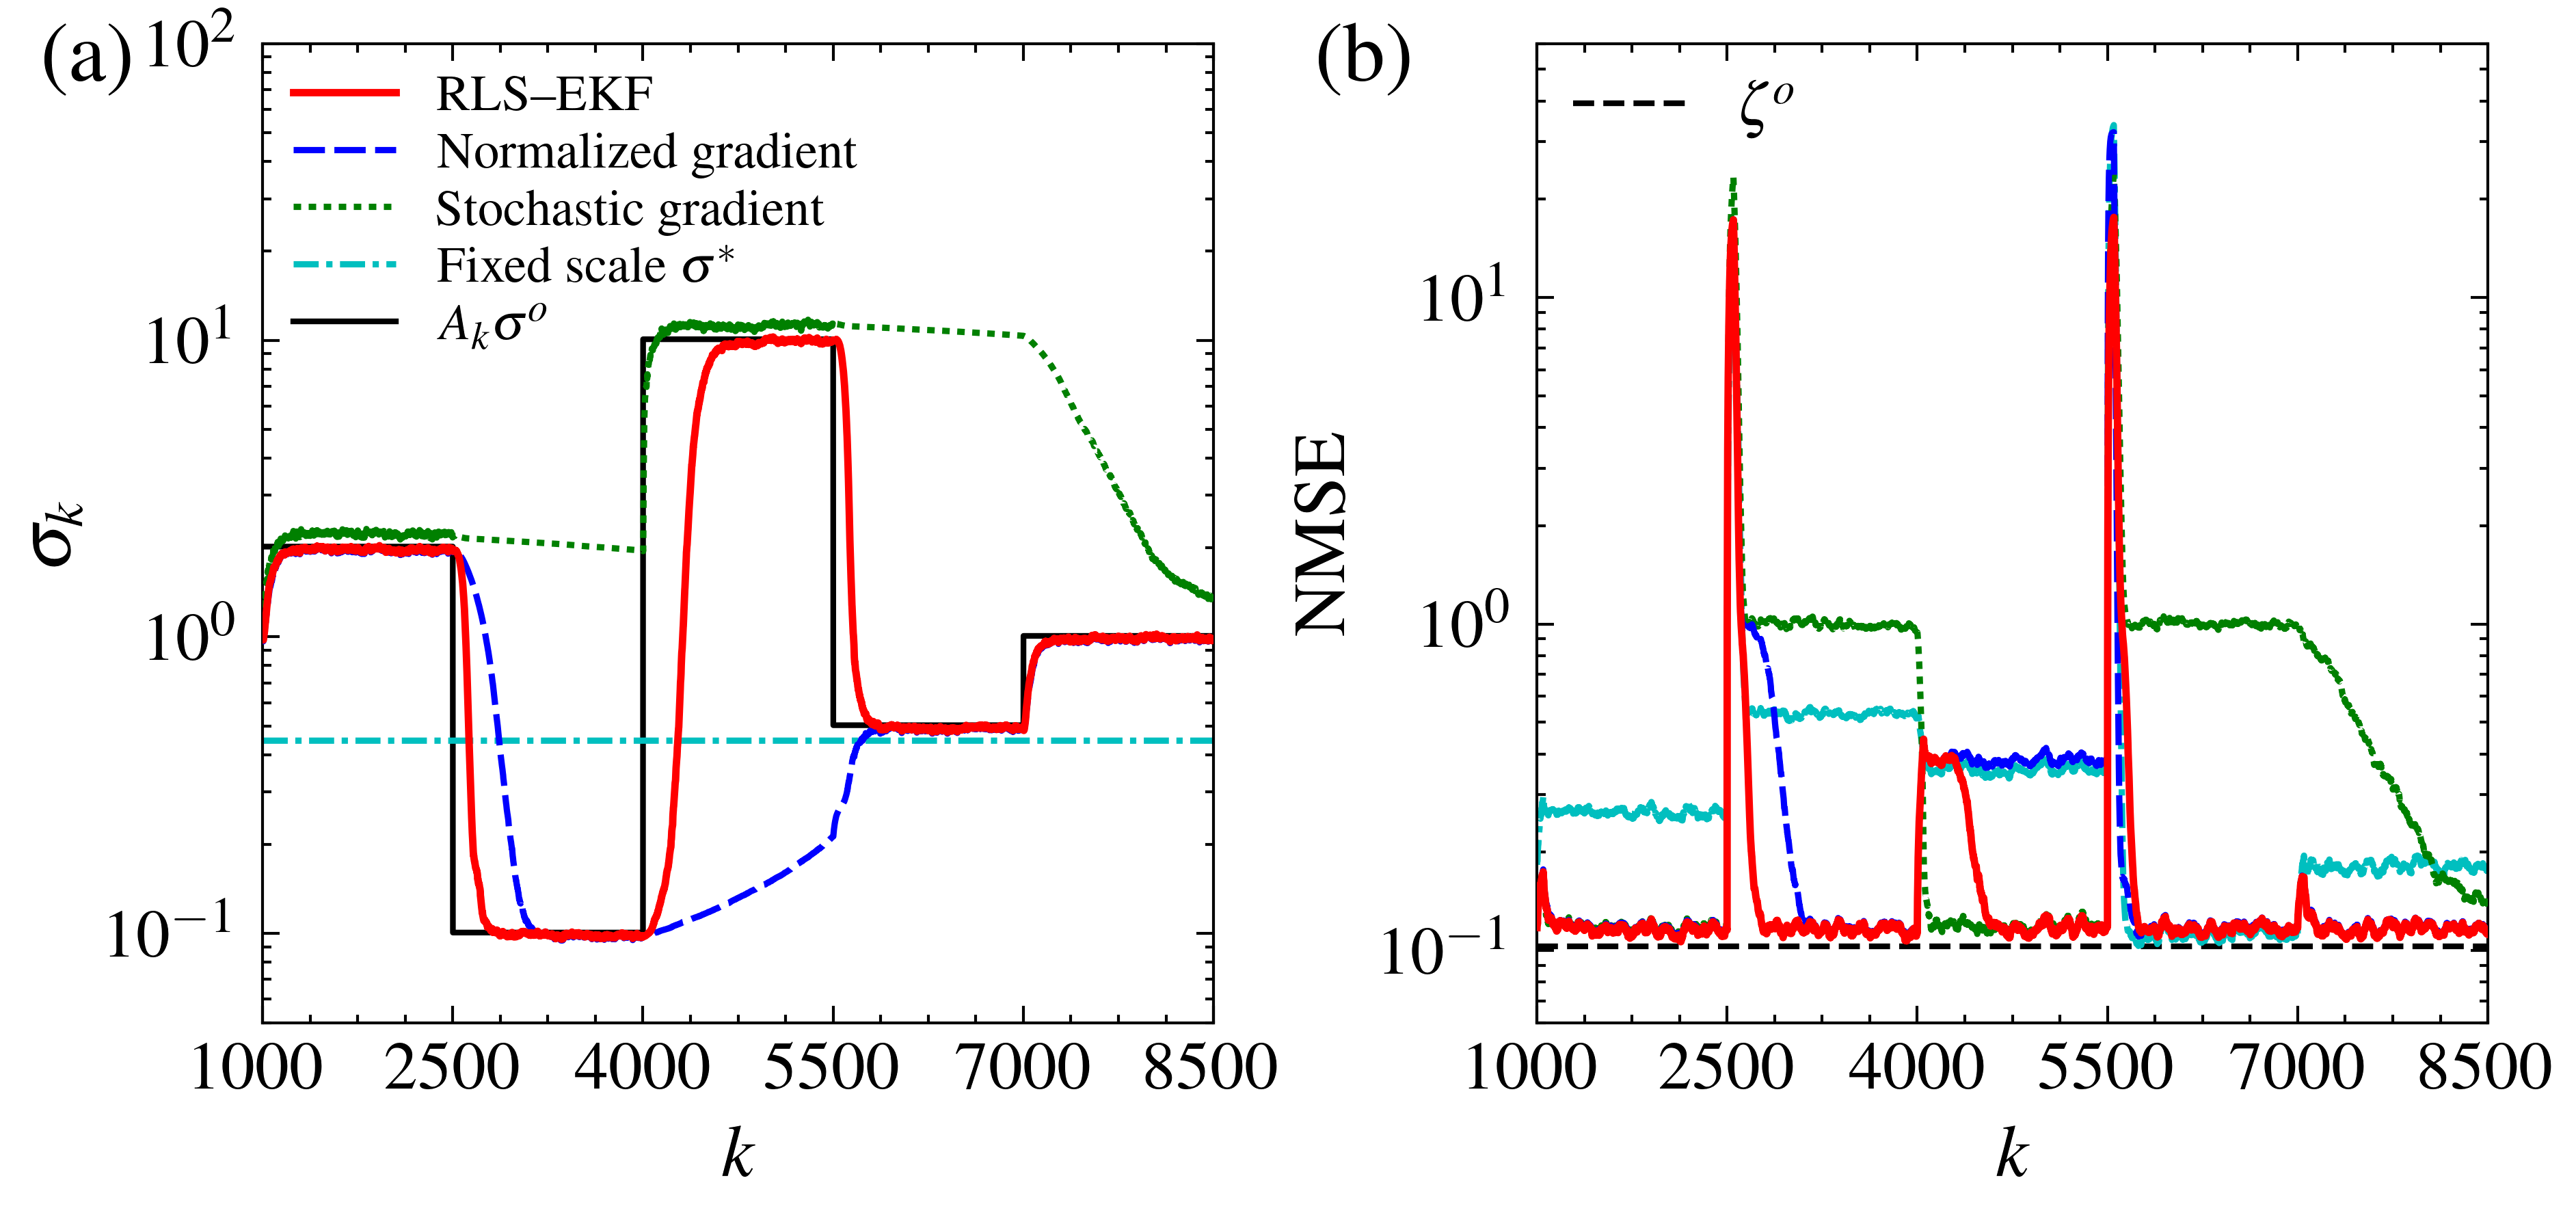

In [31]:

# ============================================================
# Cell 11. Fig. 3: Multi-step amplitude tracking (sigma_k & NMSE)
# ============================================================
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.signal import lfilter

try:
    import scienceplots  # noqa: F401
    # 1. IEEE-style plotting
    plt.style.use(["science", "ieee"])

    # 2. Override default font sizes for 50% LaTeX scaling
    matplotlib.rcParams.update({
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 13,
        "axes.titlesize": 13,
        "axes.labelsize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "axes.unicode_minus": False,
        "ps.fonttype": 42,
        "pdf.fonttype": 42
    })

except ImportError:
    # Fallback style
    matplotlib.rcParams.update({
        "font.family": "serif",
        "font.serif": [
            "Times New Roman", "Times",
            "Nimbus Roman", "DejaVu Serif"
        ],
        "mathtext.fontset": "stix",
        "font.size": 14,
        "axes.titlesize": 16,
        "axes.labelsize": 16,
        "legend.fontsize": 13,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "axes.unicode_minus": False,
        "axes.linewidth": 0.6,
        "ps.fonttype": 42,
        "pdf.fonttype": 42,
    })

WARMUP_C = 1000
SEG_LEN = 1500
# 刚好对应 Table II 的 5 个统计窗口
AMP_SEQ = (2.0, 0.1, 10.0, 0.5, 1.0)

# K_ONLINE 将等于 5 * 1500 = 7500
K_ONLINE = SEG_LEN * len(AMP_SEQ)
# K_TOTAL 将等于 1000 + 7500 = 8500
K_TOTAL = WARMUP_C + K_ONLINE 

# Time-varying amplitude envelope
A_full = np.ones(K_TOTAL, dtype=np.float64)

for idx, amp in enumerate(AMP_SEQ):
    s = WARMUP_C + idx * SEG_LEN
    e = WARMUP_C + (idx + 1) * SEG_LEN
    A_full[s:e] = amp


# Generate independent Gaussian input and dither streams
z_trk, xi_trk = make_streams(
    "gauss", TRIALS, K_TOTAL, N_EL, tag=310
)

x_trk = z_trk * A_full[None, :]
xi_trk_t = dither_to_device(xi_trk)


# ---- 2. Run the four tracking methods ----
TUNED_CFG = {
    "RLS--EKF": dict(
        rule="ekf", sigma0=REF1["sigma_o"],
        lam_f=0.93, q=0.003162, mu=0.0
    ),
    "Normalized gradient": dict(
        rule="ngrad", sigma0=REF1["sigma_o"],
        lam_f=0.93, q=0.0, mu=0.04642
    ),
    "Stochastic gradient": dict(
        rule="grad", sigma0=REF1["sigma_o"],
        lam_f=0.95, q=0.0, mu=0.5623
    ),
    "Fixed scale": dict(
        rule="fixed", sigma0=0.4467,
        lam_f=0.95, q=0.0, mu=0.0
    ),
}

# Synchronize parameters with the tuning results from Cell 10
for _cand_name in ("BEST", "TUNED", "best_params"):
    if _cand_name in globals() and isinstance(
        globals()[_cand_name], dict
    ):
        _src = globals()[_cand_name]

        for _k_lbl, _k_key in [
            ("RLS--EKF", "ekf"),
            ("Normalized gradient", "ngrad"),
            ("Stochastic gradient", "grad"),
            ("Fixed scale", "fixed"),
        ]:
            if _k_key in _src:
                for _p in ("lam_f", "q", "mu", "sigma0"):
                    if _p in _src[_k_key]:
                        TUNED_CFG[_k_lbl][_p] = float(
                            _src[_k_key][_p]
                        )


# Causal smoothing window
SMOOTH_WIN = 50
b_causal = np.ones(SMOOTH_WIN, dtype=np.float64) / SMOOTH_WIN

sigma_mean_on = {}
nmse_smooth_on = {}
A_on = A_full[WARMUP_C:]


for label, cfg in TUNED_CFG.items():

    out = simulate(
        x_trk, xi_trk_t, TH1, NS1,
        rule=cfg["rule"],
        sigma0=cfg["sigma0"],
        lam_f=cfg["lam_f"],
        q=cfg["q"],
        mu=cfg["mu"],
        rec_err=True,
        rec_sigma=True,
    )

    # Ensemble-averaged noise scale
    sigma_mean_on[label] = out["sigma"][
        :, WARMUP_C:
    ].mean(axis=0)

    # Instantaneous ensemble NMSE
    # Apply causal smoothing before extracting the online segment
    inst_nmse = (
        (out["err"] ** 2).mean(axis=0) / (A_full ** 2)
    )

    smooth_nmse = lfilter(b_causal, [1.0], inst_nmse)
    nmse_smooth_on[label] = smooth_nmse[WARMUP_C:]


del xi_trk_t, xi_trk


# ---- 3. Plot Fig. 3: noise-scale and NMSE tracking ----
# ---- 3. Plot Fig. 3: noise-scale and NMSE tracking ----
STYLES_C = {
    "RLS--EKF": dict(
        color="r", ls="-", lw=1.3, zorder=5
    ),
    "Normalized gradient": dict(
        color="b", ls=(0, (5, 1.5)),
        lw=1.1, zorder=4
    ),
    "Stochastic gradient": dict(
        color="g", ls=(0, (1.2, 1.2)),
        lw=1.1, zorder=3
    ),
    "Fixed scale": dict(
        color="c", ls=(0, (4, 1.2, 1, 1.2)),
        lw=1.1, zorder=2
    ),
}

k_on = np.arange(WARMUP_C + 1, K_TOTAL + 1)
step_ticks = [1000, 2500, 4000, 5500, 7000, 8500]

fig, (ax_a, ax_b) = plt.subplots(
    1, 2, figsize=(7.0, 3.1)
)
plt.subplots_adjust(wspace=0.34)

# ---- (a) Noise-scale tracking ----

for label in TUNED_CFG:
    st = STYLES_C[label]
    legend_label = r"Fixed scale $\sigma^\ast$" if label == "Fixed scale" else label
    ax_a.plot(
        k_on,
        sigma_mean_on[label],
        color=st["color"],
        ls=st["ls"],
        lw=st["lw"],
        zorder=st["zorder"],
        label=legend_label
    )
    
ax_a.plot(
    k_on,
    REF1["sigma_o"] * A_on,
    color="k",
    lw=1.0,
    zorder=1,
    label=r"$A_k\sigma^o$"
)
ax_a.set_xlim(1000, 8500)
ax_a.set_yscale("log")
# 将 ylim 上限从 25.0 拔高到 60.0，给图例留出充裕的“天空”
ax_a.set_ylim(0.05, 100.0) 
ax_a.set_xticks(step_ticks)
ax_a.set_ylabel(r"$\sigma_k$")

# 图 a 的内部图例（缩小字体，紧凑排列）
ax_a.legend(
    loc="upper left",
    frameon=False,
    fontsize=9,         # 缩小字体以适应空间
    handlelength=2.0,
    labelspacing=0.2,     # 压缩行距
    borderaxespad=0.2
)


# ---- (b) NMSE tracking ----
# 画出理论极限 zeta_o，并给它独立的图例标签
ax_b.axhline(
    y=REF1["zeta_o"], 
    color="k", 
    ls="--", 
    lw=1.0, 
    zorder=1, 
    label=r"$\zeta^o$"
)

for label in TUNED_CFG:
    st = STYLES_C[label]
    ax_b.plot(
        k_on,
        nmse_smooth_on[label],
        color=st["color"],
        ls=st["ls"],
        lw=st["lw"],
        zorder=st["zorder"]
    )

ax_b.set_yscale("log")
ax_b.set_xlim(1000, 8500)
# NMSE 同样拔高上限，防止极端的梯度法超出边界
ax_b.set_ylim(0.06, 60.0) 
ax_b.set_xticks(step_ticks)
ax_b.set_ylabel(r"$\mathrm{NMSE}$")

# 图 b 仅需标注 zeta_o，干净利落
ax_b.legend(
    loc="upper left",
    frameon=False,
    fontsize=10.5,
    handlelength=2.0,
    borderaxespad=0.2
)


# ---- 4. Common formatting ----
for ax, lab in zip((ax_a, ax_b), "ab"):
    ax.set_xlabel(r"$k$")
    ax.text(
        -0.23, 1.02, f"({lab})",
        transform=ax.transAxes,
        fontsize=15,
        va="top",
        ha="left"
    )
    ax.tick_params(
        direction="in", which="both", top=True, right=True, width=0.5
    )


# ---- 5. Save figures ----
for ext, kw in (("pdf", {}), ("eps", {}), ("png", {"dpi": 1000})):
    fig.savefig(os.path.join(OUT_DIR, f"FigSPL3.{ext}"), bbox_inches="tight", **kw)

plt.show()
